- Target variable - Incurred (final cost of the claim = all payments made by the insurer)
> - At stage 1, the model learns from the available claim descriptions and other available information to predict 'Incurred' and at stage 2, converts predicted cost into low, medium or high priority using MAE, RMSE and R2.
- Problem:-
> - multi-class classification problem: Severity
> - Regression problem: Incurred

# **Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# **Data Collection**

In [2]:
df = pd.read_csv("DR_Demo_Statistical_Case_Estimates.csv")

In [3]:
df.head()

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
0,15,11,28,500.00,M,S,44.0,0,0,F,5,5/10/2005,STRUCK SCAFFOLDING STRAIN LOWER BACK,3Thurs,9500,151.254501
1,22,5,29,500.00,M,S,38.0,0,0,F,5,28/10/2003,STRUCK KNIFE LACERATED LEFT THUMB,2Wed,11500,442.125024
2,22,7,28,197.37,M,M,16.0,0,0,P,3,25/05/2004,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,2Wed,8000,1494.490505
3,15,12,40,0.00,M,M,0.0,1,0,F,5,21/07/1994,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,4Fri,500,138.900000
4,38,12,22,435.70,M,M,38.0,0,0,F,5,9/06/1992,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,4Fri,320,296.160000


In [4]:
df.tail()

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
21686,23,9,53,200.00,M,M,38.0,0,0,F,5,18/06/2000,STRUCK KNIFE CUT RIGHT HAND CUT,1Tues,2650,582.166718
21687,15,13,23,500.00,M,S,40.0,0,0,F,5,23/06/2004,STRUCK WITH HAMMER FRACTURE RIGHT MIDDLE FINGER,3Thurs,1000,908.635098
21688,109,12,19,200.00,M,S,38.0,0,0,F,5,6/01/1996,STRUCK METAL GRINDING FOREIGN BODY LEFT BODY L...,2Wed,814,60.250000
21689,7,9,34,553.13,M,S,38.0,0,0,F,5,5/12/1996,STRUCK MOVING STEEL LACERATION LEFT KNEE LEFT ...,3Thurs,1500,761.625000
21690,8,11,23,200.00,M,S,38.0,0,0,F,5,16/05/2002,LIFTING BACK STRAIN LOWER BACK STRAIN LOWER BACK,4Fri,10700,1853.010547


# **Data Cleaning**

In [5]:
df.shape

(21691, 16)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21691 entries, 0 to 21690
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ReportingDelay       21691 non-null  int64  
 1   AccidentHour         21691 non-null  int64  
 2   Age                  21691 non-null  int64  
 3   WeeklyRate           21691 non-null  float64
 4   Gender               21691 non-null  str    
 5   MaritalStatus        21669 non-null  str    
 6   HoursWorkedPerWeek   21691 non-null  float64
 7   DependentChildren    21691 non-null  int64  
 8   DependentsOther      21691 non-null  int64  
 9   PartTimeFullTime     21691 non-null  str    
 10  DaysWorkedPerWeek    21691 non-null  int64  
 11  DateOfAccident       21691 non-null  str    
 12  ClaimDescription     21691 non-null  str    
 13  ReportedDay          21691 non-null  str    
 14  InitialCaseEstimate  21691 non-null  int64  
 15  Incurred             21691 non-null  float64
dt

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.dtypes

ReportingDelay           int64
AccidentHour             int64
Age                      int64
WeeklyRate             float64
Gender                     str
MaritalStatus              str
HoursWorkedPerWeek     float64
DependentChildren        int64
DependentsOther          int64
PartTimeFullTime           str
DaysWorkedPerWeek        int64
DateOfAccident             str
ClaimDescription           str
ReportedDay                str
InitialCaseEstimate      int64
Incurred               float64
dtype: object

In [9]:
df.isnull().sum()

ReportingDelay          0
AccidentHour            0
Age                     0
WeeklyRate              0
Gender                  0
MaritalStatus          22
HoursWorkedPerWeek      0
DependentChildren       0
DependentsOther         0
PartTimeFullTime        0
DaysWorkedPerWeek       0
DateOfAccident          0
ClaimDescription        0
ReportedDay             0
InitialCaseEstimate     0
Incurred                0
dtype: int64

### Investigating NULL values

In [10]:
df[df["MaritalStatus"].isnull()]

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
386,14,20,24,413.40,F,NaN,40.0,0,0,F,5,21/02/1992,STRUCK KNIFE LACERATED RIGHT WRIST,4Fri,500,39.600000
607,10,14,18,52.29,F,NaN,7.0,0,0,P,4,28/11/2000,STEPPING DOWN STAIRS SPRAINED LEFT ANKLE,4Fri,10000,1825.593147
1904,20,10,58,100.00,F,NaN,40.0,0,0,F,5,7/09/1990,STRUCK METAL IN EYE SORE RIGHT LEG,3Thurs,500,135.350000
3452,53,17,22,475.00,F,NaN,38.0,0,0,F,5,10/02/2003,STRUCK KNIFE LACERATED LEFT THUMB,4Fri,1500,358.236511
3806,169,9,48,0.00,M,NaN,0.0,0,0,F,5,15/08/1990,STRUCK KNIFE LACERATED RIGHT HAND LACERATED RI...,3Thurs,250,122.450000
5815,27,12,29,200.00,M,NaN,38.0,0,0,F,5,16/04/1997,STRUCK AGAINST DRILL BRUISED RIGHT HAND BRUISED,1Tues,600,171.832500
6965,21,14,19,204.28,M,NaN,38.0,0,0,F,5,15/04/2002,GRINDING METAL FOREIGN BODY RIGHT EYE,0Mon,500,438.034382
7441,20,10,29,467.80,M,NaN,40.0,0,0,F,5,3/07/2002,SLIPPED ON BACK STRAIN RIGHT HAND,1Tues,20748,80380.812540
8349,11,20,53,0.00,M,NaN,0.0,0,0,F,5,18/05/2000,SLIPPED ON METAL SHEET LACERATION LEFT FINGER ...,0Mon,1000,78.400153
9328,14,10,17,200.00,F,NaN,38.0,0,0,F,5,11/04/1997,FELL DOWN STAIRS BACK STRAIN,4Fri,1100,548.100000


all the individuals with missing values in Marital status have values 0 (zero) under 'dependent children' and 'dependent other'. Missing values will be retained as they seem to be connected.

In [11]:
df['MaritalStatus'] = df['MaritalStatus'].fillna('Unknown')

Missing values in MaritalStatus were replaced with an Unknown category rather than imputed using the mode, because the actual marital status of the affected individuals could not be reliably inferred from the available data.

In [12]:
# confirming missing values
df["MaritalStatus"].isnull().sum()

np.int64(0)

# **Exploratory Data Analysis**

In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ReportingDelay,21691.0,41.991148,96.169390,0.000000e+00,14.000,22.00000,42.000000,5360.000
AccidentHour,21691.0,11.505048,3.742078,0.000000e+00,9.000,11.00000,14.000000,24.000
Age,21691.0,34.002951,12.180424,1.300000e+01,24.000,32.00000,43.000000,79.000
WeeklyRate,21691.0,373.274852,272.689262,0.000000e+00,200.000,364.60000,500.000000,5811.300
HoursWorkedPerWeek,21691.0,33.792465,18.097107,0.000000e+00,38.000,38.00000,40.000000,700.000
DependentChildren,21691.0,0.112720,0.505178,0.000000e+00,0.000,0.00000,0.000000,6.000
DependentsOther,21691.0,0.008667,0.101708,0.000000e+00,0.000,0.00000,0.000000,4.000
DaysWorkedPerWeek,21691.0,4.908995,0.534661,1.000000e+00,5.000,5.00000,5.000000,7.000
InitialCaseEstimate,21691.0,6721.948504,15014.873847,1.000000e+00,500.000,1500.00000,7500.000000,500000.000
Incurred,21691.0,9647.972782,47130.506200,2.220000e-15,180.275,495.92655,1827.120743,1563322.696


- ReportingDelay: The mean reporting delay is approximately 42 days, while the median is 22 days. The maximum is 5,360 days, indicating substantial variation, with some claims reported much later than others.
- AccidentHour: The mean accident hour is approximately 11.51 and the median is 11. The maximum value of 24 requires investigation because conventional 24-hour time representation ranges from 0 to 23.
- Age: The average claimant age is approximately 34 years, with a median of 32 years and a range of 13 to 79 years. This indicates variation in claimant ages, which may be useful when investigating patterns associated with claim severity.
- WeeklyRate: The mean weekly rate is approximately 373.27, compared with a median of 364.60. The maximum value of 5,811.30 is considerably higher than the 75th percentile of 500, suggesting potential extreme values that require further investigation.
- HoursWorkedPerWeek: The mean is approximately 33.79 hours, and the median is 38 hours. The maximum value of 700 hours is unusually high and exceeds the 168 hours available in a week. This observation should be investigated as a potential data-quality issue.
- DependentChildren and DependentsOther: Both variables have a median of zero, indicating that at least half of the claimants have no dependent children or other dependants, respectively.
- DaysWorkedPerWeek: The median and 75th percentile are both five days, suggesting that a five-day working week is typical among the claimants represented in the dataset.
- InitialCaseEstimate: The mean initial case estimate is approximately 6,721.95, while the median is 1,500. The maximum value is 500,000, indicating substantial variability and likely influenced by high estimates.
- Incurred: The mean incurred claim amount is approximately 9,647.97, whereas the median is approximately 495.93. The maximum is 1,563,322.70, suggesting a strongly right-skewed distribution in which a relatively small number of high-value claims may substantially influence the mean. The minimum value, approximately zero, may reflect a genuine zero-value claim or floating-point precision.

### Inspecting the high unusual working hours

In [14]:
df[df['HoursWorkedPerWeek'] > 168] # 168 hours in a week

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
158,260,12,17,318.16,M,S,319.80,0,0,F,5,4/04/1993,STRUCK WITH KNIFE LACERATION LEFT HAND BURN TO...,0Mon,2500,725.000000
2671,21,12,19,400.00,M,S,476.85,0,0,F,5,25/07/1988,LIFTING HEAVY LIFTING STRAINED LOWER BACK INJURY,0Mon,4200,2945.910000
2720,3,6,19,400.00,M,S,400.00,0,0,F,5,8/08/1994,LIFTING INTO CONCRETE LOWER BACK STRAIN,3Thurs,5000,1097.025000
3796,60,0,48,370.00,F,M,300.00,0,0,F,5,30/04/1998,TRIPPED OVER ONTO SHOULDER STRAIN RIGHT WRIST,0Mon,20000,44100.000000
3860,14,15,29,375.00,M,S,320.00,0,0,F,5,22/12/1988,SLIPPED ON PALLET STRAIN RIGHT FOOT RIGHT THUMB,3Thurs,3500,599.637500
4586,3,14,52,380.00,F,M,338.00,0,0,F,5,31/01/1997,STRUCK WITH KNIFE LACERATION LEFT THUMB LACERA...,0Mon,330,481.950000
5323,13,9,20,442.00,M,S,400.00,0,0,F,5,2/06/1988,HIT WITH HAMMER FRACTURE TO LEFT SHOULDER TEAR,2Wed,7500,1064.740000
6190,8,9,39,657.03,F,M,400.00,1,0,F,5,30/10/2005,STRUCK KNIFE LACERATION THUMB,0Mon,500,524.348937
6505,3,10,23,400.00,M,U,400.00,0,0,F,5,10/05/2002,STRUCK WITH KNIFE LACERATED RIGHT UPPER ARM,0Mon,7500,201.148356
9640,9,15,35,500.00,F,S,225.00,0,0,F,5,25/08/2004,HIT KNIFE LACERATED RIGHT SHOULDER RIGHT HAND,4Fri,800,114.355051


all the observations are invalid because a week has 168 hours and the values range from 225 up to 700 in the rows above. 

In [15]:
# Count observations with impossible working hours
invalid_hours = (df['HoursWorkedPerWeek'] > 168)
invalid_hours.sum()

np.int64(23)

In [16]:
# Removing the rows
df = df.loc[~invalid_hours].copy()

In [17]:
# verify
print("Remaining rows:", len(df))
print("Invalid working hours remaining:",
      (df['HoursWorkedPerWeek'] > 168).sum())

Remaining rows: 21668
Invalid working hours remaining: 0


### Inspecting the large unusual reporting delays

In [18]:
df[df['ReportingDelay'] > 365] # number of days in a year

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
81,383,7,54,500.00,F,S,40.0,0,0,F,5,18/04/2004,REPETITIVE LIFTING STRAIN RIGHT FOREIGN BODY R...,4Fri,7500,3.859705e+02
201,383,10,39,976.92,M,U,84.0,0,0,F,5,23/06/2005,STRUCK WITH PERSON STRAIN RIGHT FOREARM,1Tues,1300,4.368385e+02
352,551,12,17,213.60,M,S,30.0,0,0,P,4,1/02/2001,FALL FROM LADDER FRACTURE LEFT WRIST,1Tues,9500,2.520656e+01
375,477,8,42,690.00,M,M,40.0,1,0,F,5,1/02/2001,LIFTING TROLLEY STRAIN RIGHT SHOULDER,4Fri,45000,1.310000e-13
613,684,15,27,266.27,M,M,38.0,2,2,F,5,18/02/2000,SLIPPED ON CONCRETE STRAINED NECK AND NECK AND...,2Wed,10000,8.776381e+03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20878,480,12,33,470.55,M,S,40.0,0,0,F,5,28/03/2003,LIFTING SLIPPED CUT HAND LEFT HAND,1Tues,600,3.155845e+02
20881,927,15,44,487.50,F,M,32.0,0,0,P,4,24/07/1992,LIFTING HEAVY BOX STRAINED LEFT HAND LEFT WRIST,0Mon,1500,4.889000e+02
20947,726,12,39,500.00,M,U,38.0,0,0,F,5,10/07/1992,LIFTING AND LIFTING STRAIN RIGHT WRIST,2Wed,50000,3.039203e+04
21191,437,12,53,543.78,M,M,40.0,2,0,F,5,4/12/2001,TRIPPED ON FLOOR STRAIN LEFT ELBOW,4Fri,19000,4.891749e+04


In [19]:
(df['ReportingDelay'] > 365).sum()

np.int64(177)

keeping the large reporting delays since they could be genuine

### Inspecting under 18 who are working

In [20]:
df[df['Age'] < 18][['Age', 'ClaimDescription', 'HoursWorkedPerWeek',
                     'PartTimeFullTime', 'DaysWorkedPerWeek', 'MaritalStatus', 'DependentChildren', 'DependentsOther']]

,Age,ClaimDescription,HoursWorkedPerWeek,PartTimeFullTime,DaysWorkedPerWeek,MaritalStatus,DependentChildren,DependentsOther
7,17,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN,0.0,F,5,S,0,0
79,16,FELL OFF LADDER LACERATION LEFT THUMB,38.0,F,5,S,0,0
184,16,TRIPPED ON CONCRETE FLOOR BRUISED LEFT KNEE,15.0,P,2,S,0,0
193,17,HIT METAL CUT LEFT LOWER LEFT KNEE,38.0,F,5,S,0,0
258,17,STRUCK GRINDER LACERATED RIGHT FINGERS,40.0,F,5,S,0,0
...,...,...,...,...,...,...,...,...
21427,15,STRUCK METAL DOOR STRAIN NECK AND NECK,25.5,P,3,U,0,0
21498,17,STRUCK METAL LACERATED LEFT LOWER BACK UPPER B...,5.5,P,5,S,0,0
21537,16,HIT MACHINE LOWER BACK INJURY,0.0,F,5,S,0,0
21594,16,LIFTING CARTONS BACK TWISTED LOWER BACK INJURY,12.0,P,2,S,0,0


In [21]:
# confirming min age value
df['Age'].min()

np.int64(13)

In [22]:
# locate the record
df[df['Age'] == df['Age'].min()]

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
18639,33,12,13,0.0,M,S,0.0,0,0,F,5,8/06/1990,SLIPPED ON WET FLOOR STRAINED RIGHT ELBOW,2Wed,300,729.15


## Visualizing the numerical columns

In [23]:
df.columns

Index(['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender',
       'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren',
       'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek',
       'DateOfAccident', 'ClaimDescription', 'ReportedDay',
       'InitialCaseEstimate', 'Incurred'],
      dtype='str')

In [24]:
df.dtypes

ReportingDelay           int64
AccidentHour             int64
Age                      int64
WeeklyRate             float64
Gender                     str
MaritalStatus              str
HoursWorkedPerWeek     float64
DependentChildren        int64
DependentsOther          int64
PartTimeFullTime           str
DaysWorkedPerWeek        int64
DateOfAccident             str
ClaimDescription           str
ReportedDay                str
InitialCaseEstimate      int64
Incurred               float64
dtype: object

In [25]:
# converting dateofaccident to datetime
df['DateOfAccident'] = pd.to_datetime(
    df['DateOfAccident'],
    dayfirst=True,
    errors='coerce'
)

In [26]:
df.dtypes

ReportingDelay                  int64
AccidentHour                    int64
Age                             int64
WeeklyRate                    float64
Gender                            str
MaritalStatus                     str
HoursWorkedPerWeek            float64
DependentChildren               int64
DependentsOther                 int64
PartTimeFullTime                  str
DaysWorkedPerWeek               int64
DateOfAccident         datetime64[us]
ClaimDescription                  str
ReportedDay                       str
InitialCaseEstimate             int64
Incurred                      float64
dtype: object

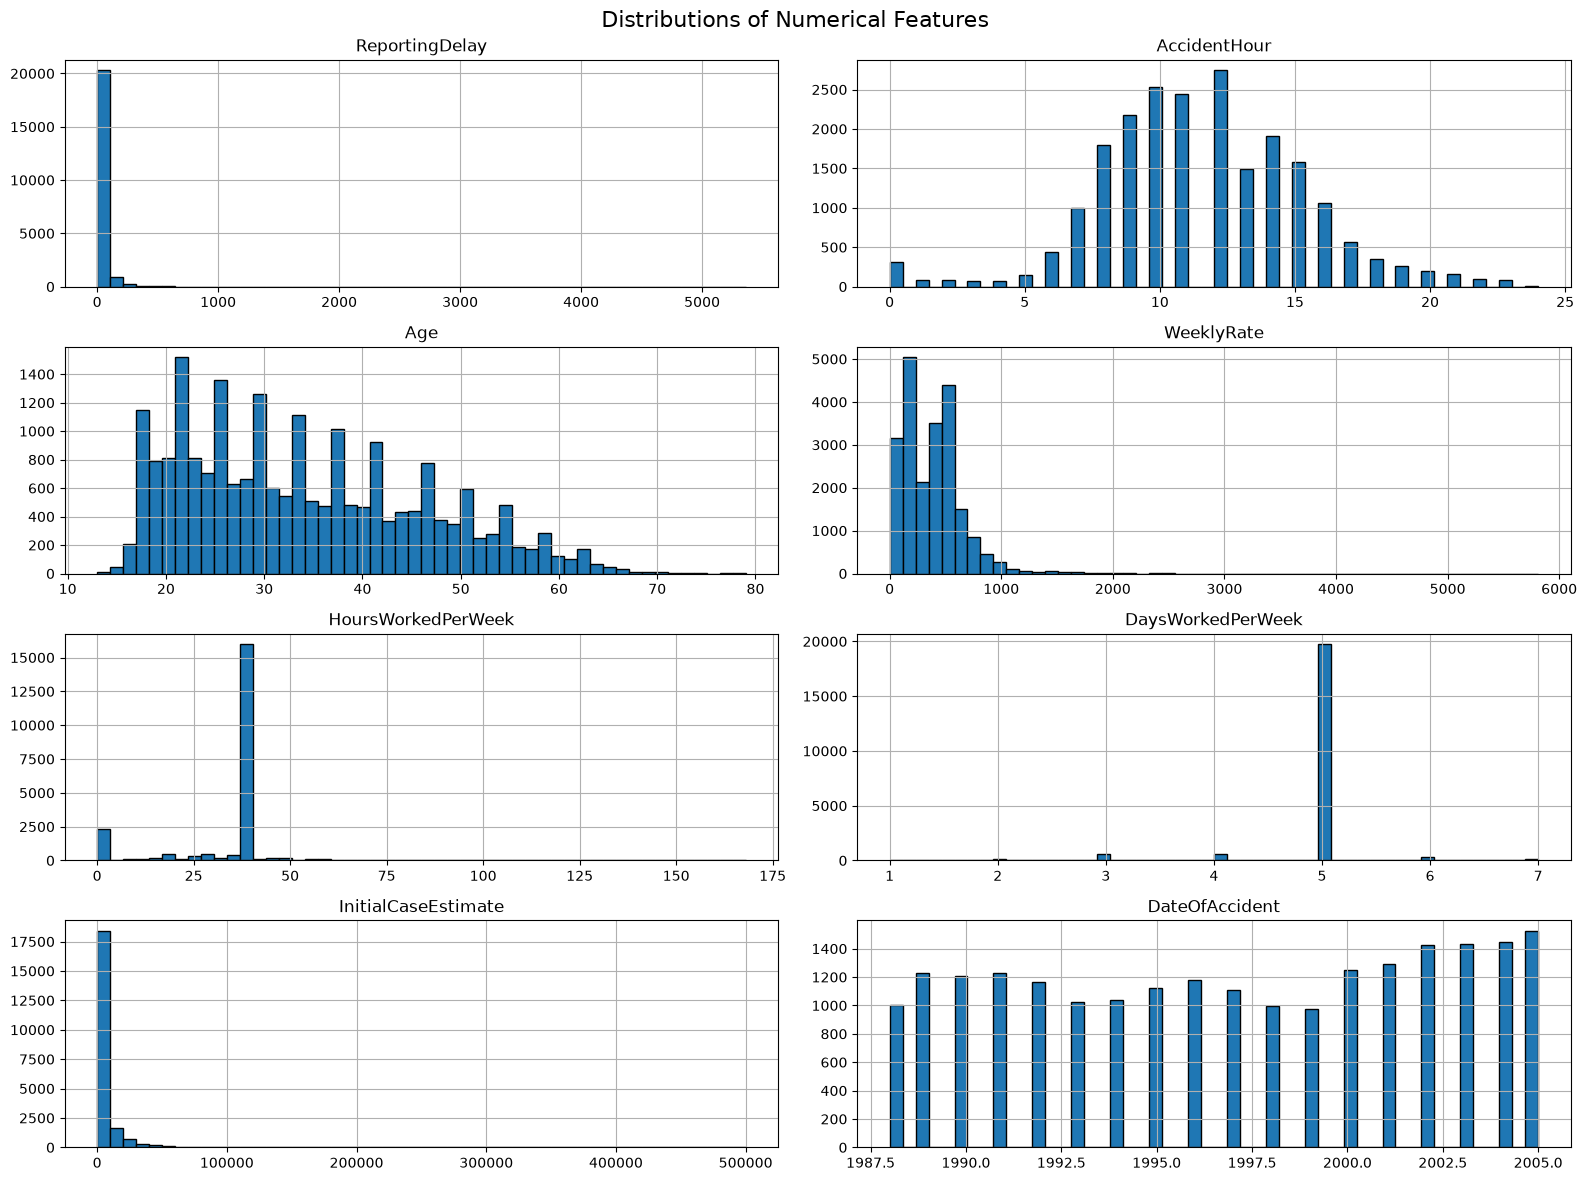

In [27]:
num_cols = [
    'ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate',
    'HoursWorkedPerWeek', 'DaysWorkedPerWeek',
    'InitialCaseEstimate', 'DateOfAccident'
]

# Create a copy for visualization
plot_df = df[num_cols].copy()

# Convert accident date to year for visualization
plot_df['DateOfAccident'] = plot_df['DateOfAccident'].dt.year

# Plot all histograms together
plot_df.hist(
    figsize=(16, 12),
    bins=50,
    layout=(4, 2),
    edgecolor='black'
)

plt.suptitle('Distributions of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

- Reporting delay is strongly right skewed.
- AccidentHour is almost normal.
- Age is right skewed.
- WeeklyRate is right skwewed.
- HoursWorkedPerWeek, most observations are concentrated around 38–40 hours per week.
- DaysWorkedPerWeek, most observations are concentrated at five days per week.
- InitialCaseEstimate is strongly right skewed.
- Date of accident is somehow normal.

## Visualizing the categorical columns

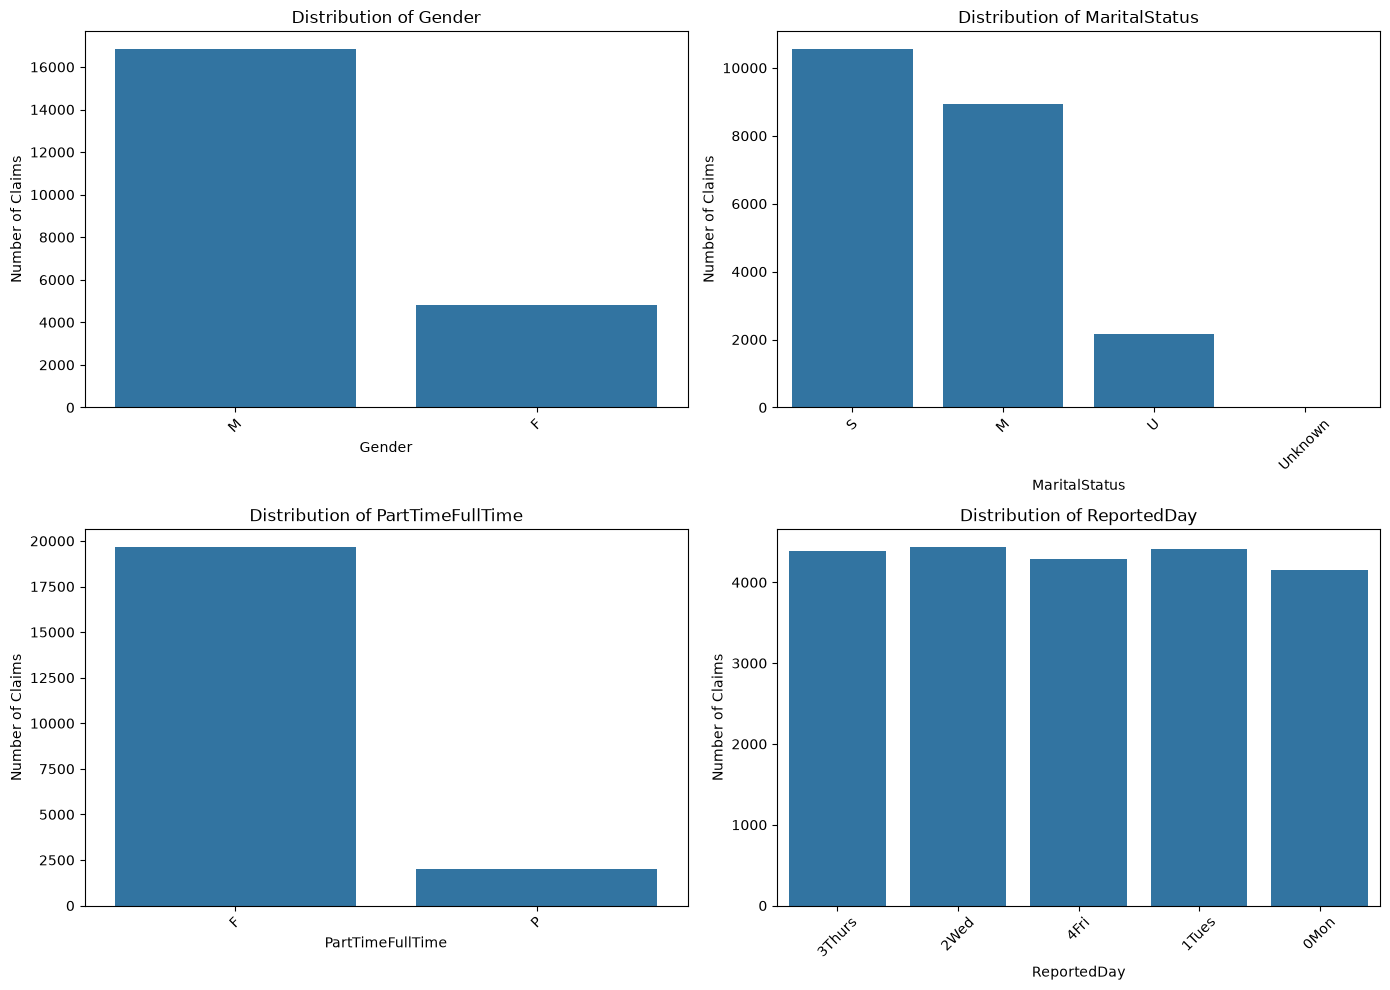

In [28]:
cat_cols = [
    'Gender',
    'MaritalStatus',
    'PartTimeFullTime',
    'ReportedDay'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Number of Claims')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

- Male are more compared to female.
- Single people are leading, followed by Married and lastly U (unknown)
- Full time employees are so many compared to part-time employees.
- The distribution of reportedDays is almost equal

In [29]:
df['MaritalStatus'].value_counts(dropna=False)

MaritalStatus
S          10549
M           8947
U           2150
Unknown       22
Name: count, dtype: int64

### Correlation heatmap

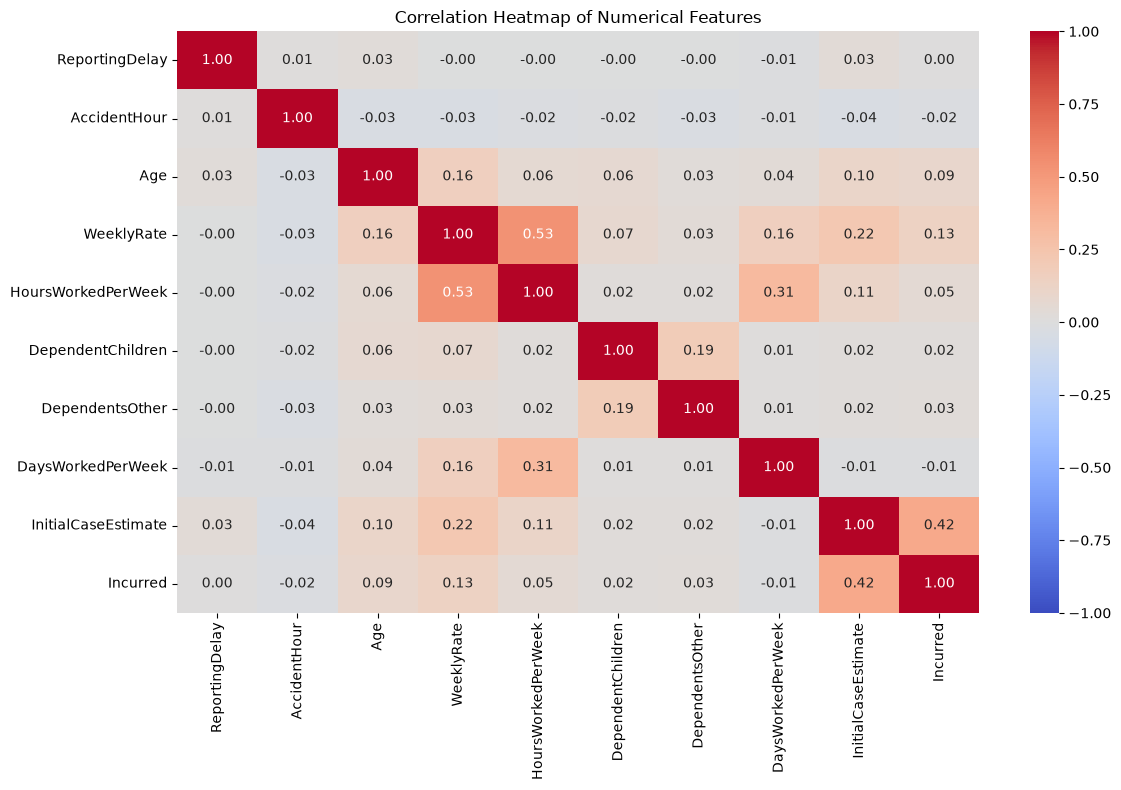

In [30]:
# Select numerical columns only
num_df = df.select_dtypes(include='number')

# Calculate correlations
corr = num_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

## VIF for multicollinearity.
- VIF = 1: no multicollinearity
- VIF </= 5: Moderate multicollinearity
- VIF > 5 (or 10): High multicollinearity

In [31]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numerical predictor variables
vif_cols = [
    'ReportingDelay',
    'AccidentHour',
    'Age',
    'WeeklyRate',
    'HoursWorkedPerWeek',
    'DependentChildren',
    'DependentsOther',
    'DaysWorkedPerWeek',
    'InitialCaseEstimate'
]

# Prepare data for VIF
X_vif = df[vif_cols].dropna()

# Calculate VIF
vif_data = pd.DataFrame()
vif_data['Feature'] = X_vif.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_data = vif_data.sort_values('VIF', ascending=False)
vif_data.round(2)

,Feature,VIF
4,HoursWorkedPerWeek,1.52
3,WeeklyRate,1.49
7,DaysWorkedPerWeek,1.11
8,InitialCaseEstimate,1.06
5,DependentChildren,1.05
6,DependentsOther,1.04
2,Age,1.04
1,AccidentHour,1.00
0,ReportingDelay,1.00


ReportingDelay and AccidentHour have almost no multicollinearity, while the rest have a low multicollinearity

## Outlier Treatment

In [32]:
numerical_cols = [
    'ReportingDelay',
    'AccidentHour',
    'Age',
    'WeeklyRate',
    'HoursWorkedPerWeek',
    'DependentChildren',
    'DependentsOther',
    'DaysWorkedPerWeek',
    'InitialCaseEstimate',
    'Incurred'
]

outlier_results = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outlier_results.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage (%)': len(outliers) / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)
outlier_summary.round(2)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,ReportingDelay,-28.00,84.00,2042,9.42
1,AccidentHour,1.50,21.50,584,2.70
2,Age,-4.50,71.50,12,0.06
3,WeeklyRate,-250.00,950.00,572,2.64
4,HoursWorkedPerWeek,35.00,43.00,5165,23.84
5,DependentChildren,0.00,0.00,1267,5.85
6,DependentsOther,0.00,0.00,172,0.79
7,DaysWorkedPerWeek,5.00,5.00,1934,8.93
8,InitialCaseEstimate,-10000.00,18000.00,1924,8.88
9,Incurred,-2288.16,4294.27,3397,15.68


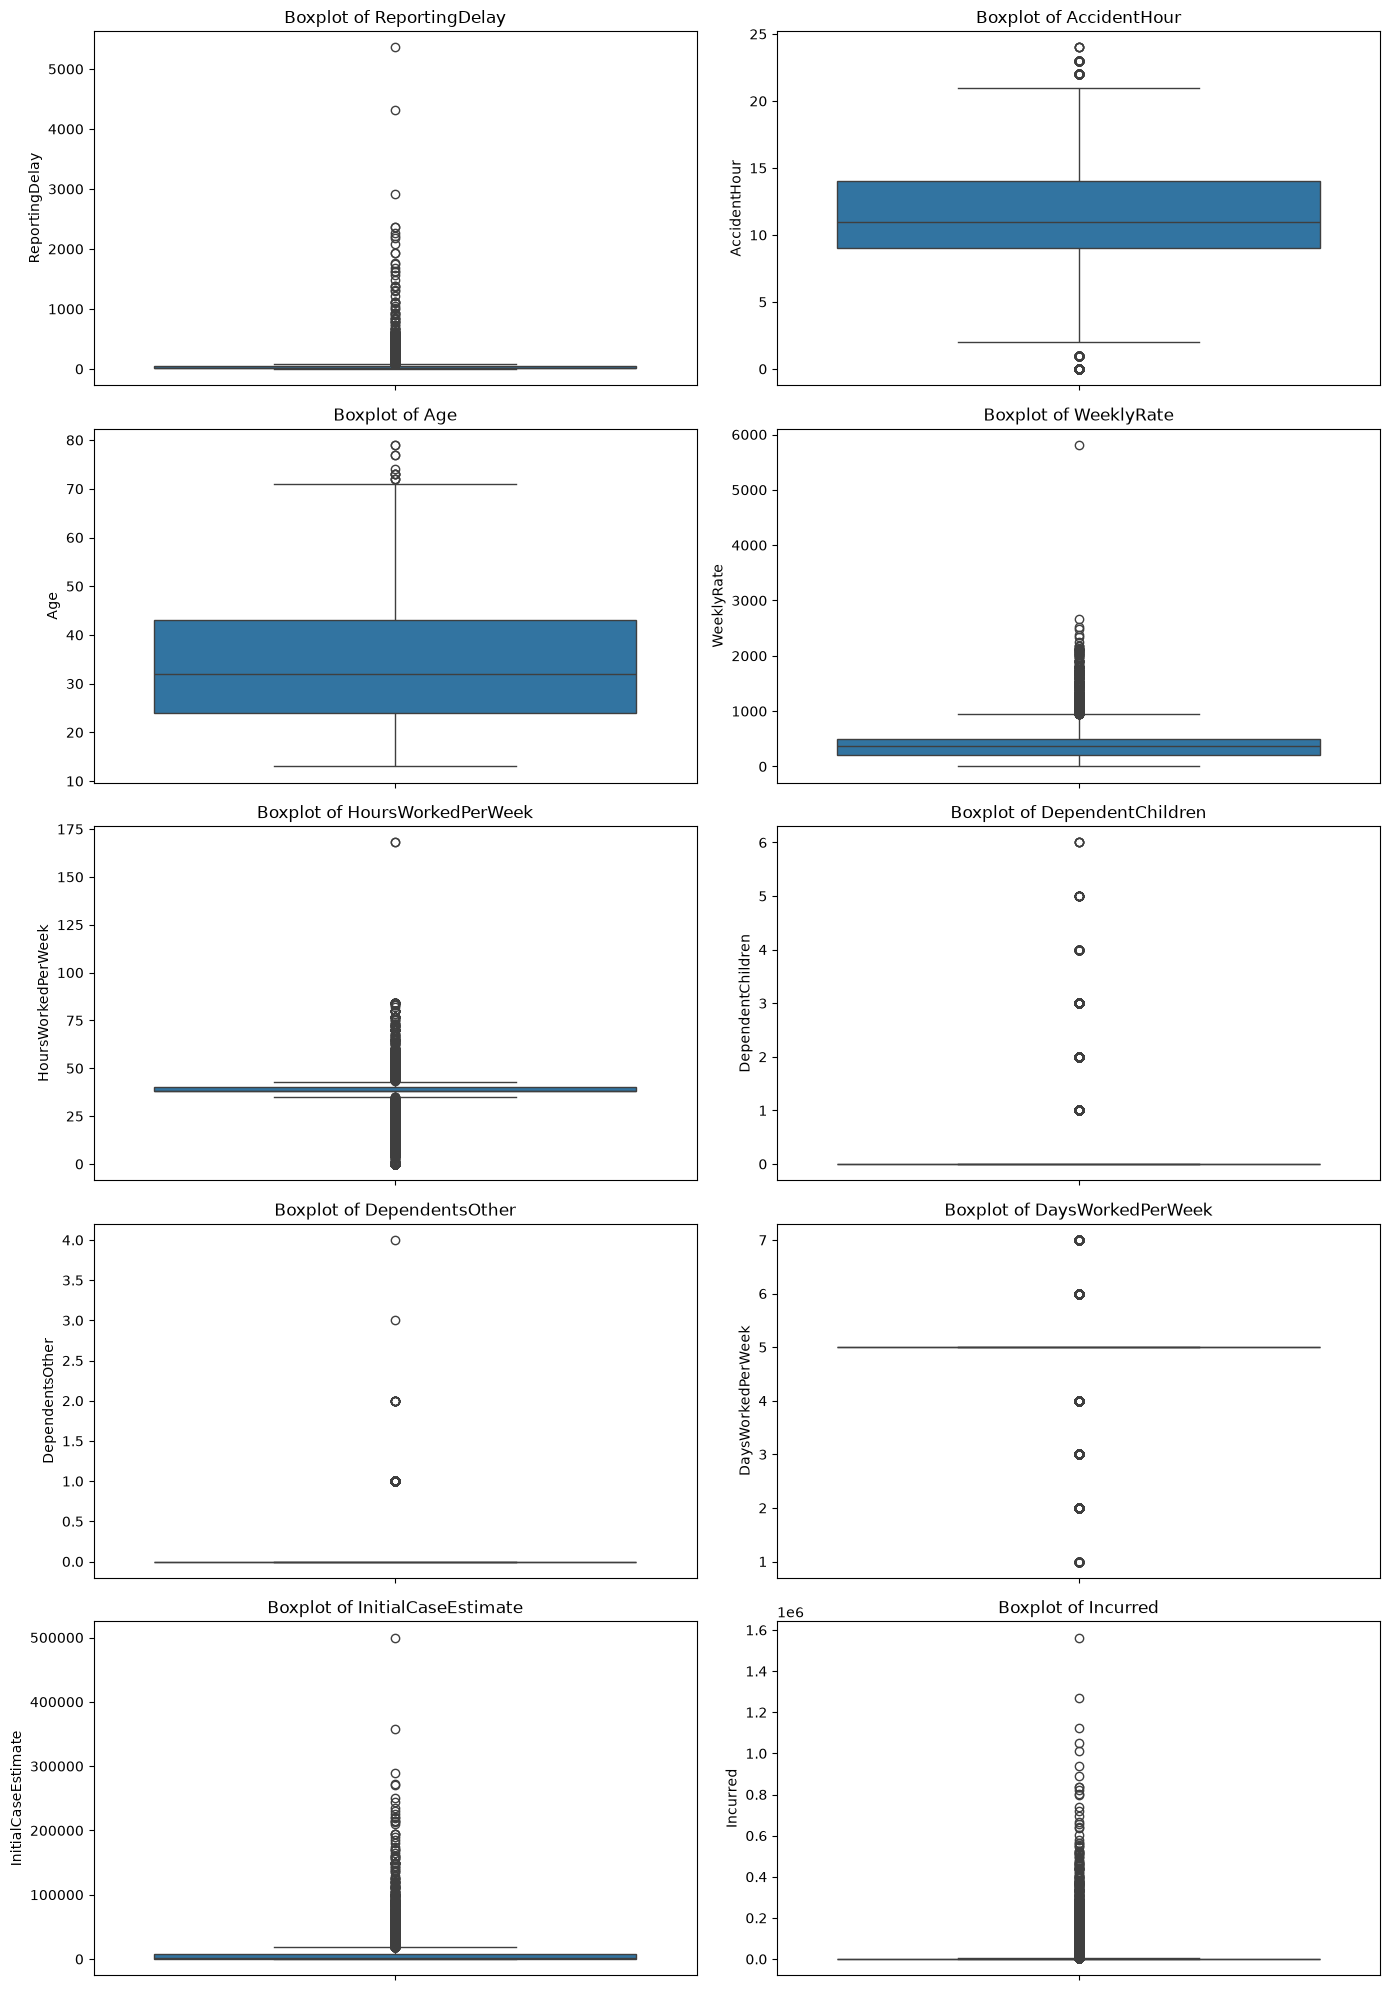

In [33]:
fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(f'Boxplot of {col}')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

The boxplots reveal potential outliers in several numerical features, particularly ReportingDelay, WeeklyRate, HoursWorkedPerWeek, InitialCaseEstimate and Incurred. Several features, including the number of dependants and days worked per week, are naturally discrete and concentrated around particular values.

Outlier detection alone is not sufficient reason to delete observations hence the next step is to investigate implausible values and distinguish genuine extreme observations from data errors. Since Incurred is the target for claim severity prediction, unusually high claim amounts should be retained unless there is evidence that they are incorrect. If the target is later converted into low, medium and high severity classes, these extreme amounts will also influence the choice of severity thresholds.

The boxplots for DependentChildren and DependentsOther look unusual because these are count variables with many zeros. The IQR method flags legitimate nonzero values simply because most observations are zero. This does not mean those records are erroneous.

### Investigating AccidentHour

In [34]:
print("Minimum:", df['AccidentHour'].min())
print("Maximum:", df['AccidentHour'].max())

df.loc[
    (df['AccidentHour'] < 0) | (df['AccidentHour'] > 23),
    ['AccidentHour', 'DateOfAccident', 'ClaimDescription']
]

Minimum: 0
Maximum: 24


,AccidentHour,DateOfAccident,ClaimDescription
6421,24,1988-02-27,STRUCK METAL BAR STRAIN RIGHT SHOULDER INJURY
10688,24,1994-06-08,HIT ARM ON HAND LACERATION LEFT LOWER LEFT HAND
12027,24,1994-02-20,FELL FROM MACHINE LACERATION TO RIGHT ELBOW
19938,24,2003-08-04,SLIPPED KNIFE LACERATED LEFT FINGER


In the conventional 24-hour clock, valid hour values are 0–23, so 24 is outside the expected range.

 The observations have an `AccidentHour` value of 24. Since the available dataset documentation does not clarify the meaning of this value, the observations will be retained during EDA without modification. Their treatment will be reviewed during preprocessing to avoid making unsupported assumptions or unnecessarily removing data.

### Investigating WeeklyRate

In [35]:
Q1 = df['WeeklyRate'].quantile(0.25)
Q3 = df['WeeklyRate'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Upper IQR bound:", upper_bound)
print("Outlier count:", (df['WeeklyRate'] > upper_bound).sum())

df.loc[
    df['WeeklyRate'] > upper_bound,
    ['WeeklyRate', 'Age', 'HoursWorkedPerWeek',
     'PartTimeFullTime', 'InitialCaseEstimate', 'Incurred']
].sort_values('WeeklyRate', ascending=False).head(15)

Upper IQR bound: 950.0
Outlier count: 572


,WeeklyRate,Age,HoursWorkedPerWeek,PartTimeFullTime,InitialCaseEstimate,Incurred
7163,5811.30,59,65.00,F,20000,5487.785455
4033,2674.00,58,56.00,F,10000,2772.844053
10900,2522.03,24,56.00,F,990,406.359345
13591,2487.00,48,38.00,F,56625,639076.468900
8727,2380.93,24,56.00,F,440,206.843762
10475,2335.00,39,84.00,F,12000,2619.844308
16043,2246.00,25,59.00,F,55000,3297.121061
1444,2178.90,39,30.00,F,1000,1227.868896
21009,2171.32,52,54.00,F,700,230.864977
6027,2168.56,54,40.00,F,500,237.940682


Outliers will be kept since they may represent legitimate observations thus scaling (Robustscaler) will be considered during the preprocessing step

### Investigating InitialCaseEstimate

In [36]:
Q1 = df['InitialCaseEstimate'].quantile(0.25)
Q3 = df['InitialCaseEstimate'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Upper IQR bound:", upper_bound)
print("Outlier count:",
      (df['InitialCaseEstimate'] > upper_bound).sum())

df.loc[
    df['InitialCaseEstimate'] > upper_bound,
    ['InitialCaseEstimate', 'Incurred',
     'ClaimDescription', 'ReportingDelay']
].sort_values('InitialCaseEstimate', ascending=False).head(15)

Upper IQR bound: 18000.0
Outlier count: 1924


,InitialCaseEstimate,Incurred,ClaimDescription,ReportingDelay
4002,500000,4.599808e+05,BENDING CLEANING STRAIN LOWER BACK STRAIN LOWE...,20
8991,358000,3.963779e+05,LIFTING LOWER BACK STRAIN,94
591,290000,4.755062e+05,LIFTING REPETITIVE STRAIN BACK STRAIN LOWER BA...,40
6250,272000,1.563323e+06,FELL DOWN LOWER BACK LOWER BACK PAIN,25
7702,270000,3.963779e+05,FELL OFF LADDER BACK STRAIN RIGHT SHOULDER STRAIN,13
15479,250297,5.083576e+04,LIFTING CHILD STRAIN BACK STRAIN UPPER BACK ST...,15
7128,245000,8.253917e+03,FELL DOWN STAIRS STRAIN LEFT FINGERS,28
11562,235000,3.657718e+04,LIFTING STRAIN RIGHT KNEE,54
20412,230069,2.682134e+04,STRUCK FORKLIFT LOW BACK STRAIN,193
15047,225000,6.025641e+05,LIFTING RESIDENT LOWER BACK INJURY,49


The InitialCaseEstimate variable has 1,924 observations above the upper IQR bound of 18,000. These observations are flagged as potential outliers, but they will be retained pending further investigation because high initial claim estimates may be legitimate. Their distribution and relationship with the Incurred target will be examined before deciding on any preprocessing

Some claims have high initial estimates but much lower Incurred values. This is worth exploring, as the initial estimate may not match the final cost.

### Scatter plot for InitialCaseEstimate vs. Incurred 

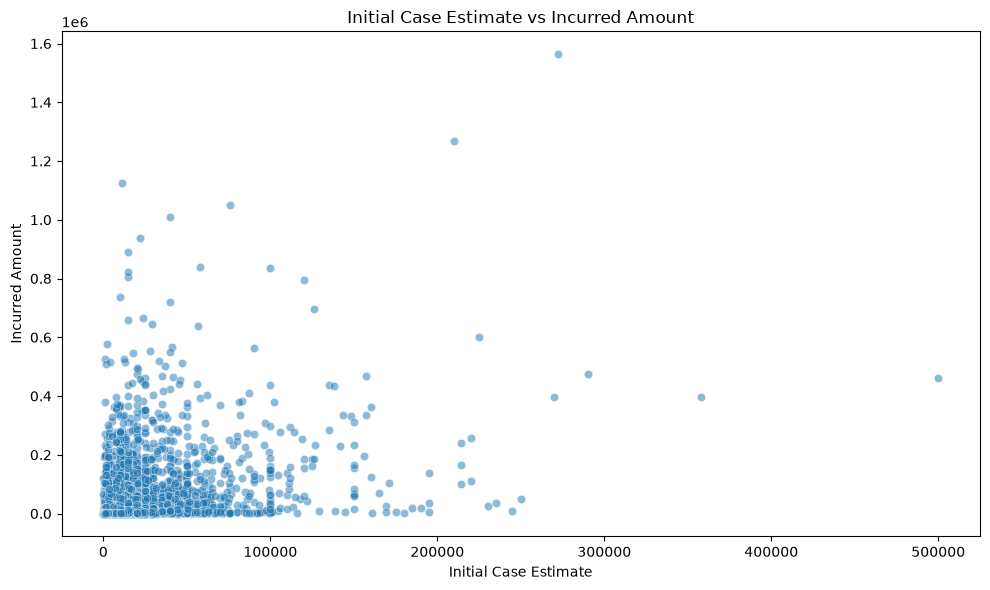

In [37]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='InitialCaseEstimate',
    y='Incurred',
    alpha=0.5
)

plt.title('Initial Case Estimate vs Incurred Amount')
plt.xlabel('Initial Case Estimate')
plt.ylabel('Incurred Amount')
plt.tight_layout()
plt.show()

- Both cases have both a low initial estimate and a low final incurred amount. 
- There are cases that were estimated very low but ended up costing a massive amount (the vertical outliers)
- 

### Investigating Incurred

In [38]:
Q1 = df['Incurred'].quantile(0.25)
Q3 = df['Incurred'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Upper IQR bound:", upper_bound)
print("Outlier count:", (df['Incurred'] > upper_bound).sum())

df.loc[
    df['Incurred'] > upper_bound,
    ['Incurred', 'InitialCaseEstimate', 'ClaimDescription',
     'Age', 'ReportingDelay']
].sort_values('Incurred', ascending=False).head(15)

Upper IQR bound: 4294.26682875
Outlier count: 3397


,Incurred,InitialCaseEstimate,ClaimDescription,Age,ReportingDelay
6250,1.563323e+06,272000,FELL DOWN LOWER BACK LOWER BACK PAIN,46,25
4854,1.269778e+06,210000,LIFTING LOWER BACK STRAIN LOWER BACK STRAIN,41,13
4316,1.124836e+06,11000,LIFTING BAGS BACK STRAIN LOWER BACK PAIN,49,28
3509,1.050411e+06,76000,SLIPPED ON STEP STRAIN RIGHT KNEE BACK STRAIN,41,6
8470,1.011132e+06,40000,STRUCK FALLING BOX LOWER BACK STRAIN LEFT LEG,33,8
7554,9.373632e+05,22000,LIFTING BOX STRAINED LOWER BACK STRAIN BACK,42,40
803,8.913606e+05,14500,TWISTED BACK STRAIN LOWER BACK STRAIN,26,63
6995,8.378862e+05,58115,LIFTING TRUCK BACK STRAIN LOWER BACK STRAIN,35,16
7304,8.345769e+05,100000,FALL OVER BACK STRAIN LOWER BACK INJURY,34,15
18000,8.234933e+05,15000,FELL FROM LADDER BACK SPRAIN,33,42


### Investigating DaysWorkedPerWeek

In [39]:
print(df['DaysWorkedPerWeek'].value_counts().sort_index())

DaysWorkedPerWeek
1       62
2      177
3      580
4      635
5    19734
6      360
7      120
Name: count, dtype: int64


# **Data Preprocessing**

# Creating a new target variable 'Severity'

Converting the continuous incurred amounts into three categories: Low, Medium and High severity through a process called *target variable descretisation or binning* (the process of converting a continuous numerical target variable into a finite set of discrete classes, bins or categories) since there is an abscence of established cost thresholds. Creation of a new column named "severity' and then categorize the thresholds into 33rd and 67th percentiles to divide into the three groups such that: claims below 33rd percentile are low severity, claims above 33rd but below 67th percentile are medium severity and lastly, claims above the 67th percentile are high severity. And also create some class balance.

In [40]:
# Checking Incurred distribution
df['Incurred'].describe(percentiles=[0.33, 0.50, 0.67])

count    2.166800e+04
mean     9.630120e+03
std      4.704018e+04
min      2.220000e-15
33%      2.484248e+02
50%      4.958777e+02
67%      1.121230e+03
max      1.563323e+06
Name: Incurred, dtype: float64

In [41]:
# Calculate the severity thresholds
lower_threshold = df['Incurred'].quantile(0.33)
upper_threshold = df['Incurred'].quantile(0.67)

print("Low severity upper limit:", lower_threshold)
print("Medium severity upper limit:", upper_threshold)

Low severity upper limit: 248.42475000000013
Medium severity upper limit: 1121.22955804


In [42]:
# Creating severity categories
df['Severity'] = np.select(
    [
        df['Incurred'] <= lower_threshold,
        df['Incurred'] <= upper_threshold
    ],
    [
        'Low',
        'Medium'
    ],
    default='High'
)

In [43]:
# Check resulting classes
print(df['Severity'].value_counts())

print("\nClass percentages:")
print((df['Severity'].value_counts(normalize=True) * 100).round(2))

Severity
Medium    7366
Low       7151
High      7151
Name: count, dtype: int64

Class percentages:
Severity
Medium    33.99
Low       33.00
High      33.00
Name: proportion, dtype: float64


The classes are nearly equally represented but medium has slightly more claims.

In [127]:
df.head(30)

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred,Severity,ClaimDescription_Lemmatized,ClaimDescription_Stemmed
0,15,11,28,500.00,M,S,44.0,0,0,F,5,2005-10-05,STRUCK SCAFFOLDING STRAIN LOWER BACK,3Thurs,9500,151.254501,Low,strike scaffold strain lower back,strike scaffold strain lower back
1,22,5,29,500.00,M,S,38.0,0,0,F,5,2003-10-28,STRUCK KNIFE LACERATED LEFT THUMB,2Wed,11500,442.125024,Medium,strike knife lacerate leave thumb,strike knife lacer left thumb
2,22,7,28,197.37,M,M,16.0,0,0,P,3,2004-05-25,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,2Wed,8000,1494.490505,High,slip and hit strain leave shoulder injury leav...,slip and hit strain left shoulder injuri left ...
3,15,12,40,0.00,M,M,0.0,1,0,F,5,1994-07-21,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,4Fri,500,138.900000,Low,hit fall door laceration leave shoulder injury...,hit fall door lacer left shoulder injuri right...
4,38,12,22,435.70,M,M,38.0,0,0,F,5,1992-06-09,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,4Fri,320,296.160000,Medium,strike fall object laceration right ring finger,strike fall object lacer right ring finger
5,55,7,18,263.45,F,Unknown,40.0,0,0,F,5,1993-06-09,KNIFE SLIPPED CUT LEFT INDEX FINGER,1Tues,210,99.200000,Low,knife slip cut leave index finger,knife slip cut left index finger
6,6,14,22,200.00,M,S,38.0,0,0,F,5,1995-04-20,SLIPPED ON STEEL BEAM LOWER BACK BRUISING KNEE...,2Wed,4000,154.625000,Low,slip on steel beam lower back bruise knee liga...,slip on steel beam lower back bruis knee ligament
7,105,7,17,0.00,M,S,0.0,0,0,F,5,1994-05-17,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN,1Tues,500,252.500000,Medium,lift metal sheet strain lower back pain,lift metal sheet strain lower back pain
8,14,9,61,1446.00,M,M,60.0,0,0,F,5,2004-11-23,LIFTING PATIENT BACK PAIN,1Tues,5000,534.100143,Medium,lift patient back pain,lift patient back pain
9,10,12,62,461.90,M,M,25.0,0,0,P,4,1995-11-13,SLIPPED OFF TRUCK BRUISED LOWER BACK RIGHT KNEE,3Thurs,5000,766.425000,Medium,slip off truck bruise lower back right knee,slip off truck bruis lower back right knee


In [45]:
# Checking if creating 'Severity' created missing values
df['Severity'].isna().sum()

np.int64(0)

### Combining 'unknown' and 'U'

In [46]:
df['MaritalStatus'] = df['MaritalStatus'].replace({
    'U': 'Unknown',
    'Unknown': 'Unknown'
})

In [47]:
print(df['MaritalStatus'].value_counts())

MaritalStatus
S          10549
M           8947
Unknown     2172
Name: count, dtype: int64


### Research on:-
impact of creating severity column from incurred column only.
> - ANS: Think of it this way: you know the final incurred amount for historical claims, so you use it to label them Low, Medium or High. The model then learns from the other available information to predict the severity of a new claim. The model learns from the available features by learning patterns connecting the available features to the severity labels. For a new claim, it receives the description, age and other eligible features, then predicts Low, Medium or High. It does not need the new claim's final Incurred amount to make that prediction.

# Extracting keywords from 'ClaimDescription'

In [48]:
# checking few descriptions in order to build the keyword categories
df['ClaimDescription'].head(30)

0                  STRUCK SCAFFOLDING STRAIN LOWER BACK
1                     STRUCK KNIFE LACERATED LEFT THUMB
2     SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...
3     HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...
4     STRUCK FALLING OBJECT LACERATION RIGHT RING FI...
5                   KNIFE SLIPPED CUT LEFT INDEX FINGER
6     SLIPPED ON STEEL BEAM LOWER BACK BRUISING KNEE...
7           LIFTING METAL SHEETS STRAIN LOWER BACK PAIN
8                             LIFTING PATIENT BACK PAIN
9       SLIPPED OFF TRUCK BRUISED LOWER BACK RIGHT KNEE
10    SLIPPED CUTTING WITH KNIFE LACERATION RIGHT IN...
11                        LIFTING PIPE LOWER BACK LOWER
12              HIT IN STEEL LOWER BACK STRAIN AND KNEE
13    LIFTING RESIDENT LACERATION LEFT ARM LEFT SHOU...
14    STRUCK KNIFE LACERATION LEFT THUMB INJURY HAND...
15               FELL DOWN LOWER BACK STRAIN LOWER BACK
16           LIFTING HEAVY LIFTING BACK LEFT EYE INJURY
17           LIFTING BACK STRAIN LOWER BACK INJU

Common keywords:- 

- **How accident happened**: struck, fell, strained, slipped, lifting, caught, hit, falling , cutting, cut
- **Injury type**: strain, sprain, strained, laceration, lacerated, bruise, bruised, fracture, crush, injury, pain, cut
- **Body part**: back, shoulder, knee, thumb, finger, hand, arm, leg, wrist, neck, eye, ankle, groin, head



### Stemming vs. Lemmatization
- Stemming - is a rule-based text normalisation technique that reduces words to their root form by removing prefixes or suffixes such as -ing, -ed, -es
- Lemmatization -  is a linguistically driven text normalization technique that converts words into their base dictionary form, known as a lemma, by considering grammar, vocabulary and context.

# Using Lemmatization

In [49]:
# # installing packages
# %pip install nltk

In [50]:
import nltk

nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [51]:
from nltk.stem import WordNetLemmatizer
import re

lemmatizer = WordNetLemmatizer()

def lemmatize_description(description):
    words = re.findall(r'\b[a-zA-Z]+\b', str(description).lower())
    return " ".join(lemmatizer.lemmatize(word, pos='v') for word in words)

df['ClaimDescription_Lemmatized'] = df['ClaimDescription'].apply(
    lemmatize_description
)

df[['ClaimDescription', 'ClaimDescription_Lemmatized']].head(30)

,ClaimDescription,ClaimDescription_Lemmatized
0,STRUCK SCAFFOLDING STRAIN LOWER BACK,strike scaffold strain lower back
1,STRUCK KNIFE LACERATED LEFT THUMB,strike knife lacerate leave thumb
2,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,slip and hit strain leave shoulder injury leav...
3,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,hit fall door laceration leave shoulder injury...
4,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,strike fall object laceration right ring finger
5,KNIFE SLIPPED CUT LEFT INDEX FINGER,knife slip cut leave index finger
6,SLIPPED ON STEEL BEAM LOWER BACK BRUISING KNEE...,slip on steel beam lower back bruise knee liga...
7,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN,lift metal sheet strain lower back pain
8,LIFTING PATIENT BACK PAIN,lift patient back pain
9,SLIPPED OFF TRUCK BRUISED LOWER BACK RIGHT KNEE,slip off truck bruise lower back right knee


- words have been lemmatized but 'left thumb' has been converted to 'leave thumb'
- laceration has not been converted to lacerate like the way lacerated was

# Using Stemming

In [52]:
import re
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

# Normalize important irregular terms before stemming
word_map = {
    'fell': 'fall',
    'fallen': 'fall',
    'struck': 'strike'
}

def stem_description(description):
    words = re.findall(r'\b[a-zA-Z]+\b', str(description).lower())

    words = [word_map.get(word, word) for word in words]

    return " ".join(stemmer.stem(word) for word in words)

df['ClaimDescription_Stemmed'] = df['ClaimDescription'].apply(
    stem_description
)

df[['ClaimDescription', 'ClaimDescription_Stemmed']].head(30)

,ClaimDescription,ClaimDescription_Stemmed
0,STRUCK SCAFFOLDING STRAIN LOWER BACK,strike scaffold strain lower back
1,STRUCK KNIFE LACERATED LEFT THUMB,strike knife lacer left thumb
2,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,slip and hit strain left shoulder injuri left ...
3,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,hit fall door lacer left shoulder injuri right...
4,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,strike fall object lacer right ring finger
5,KNIFE SLIPPED CUT LEFT INDEX FINGER,knife slip cut left index finger
6,SLIPPED ON STEEL BEAM LOWER BACK BRUISING KNEE...,slip on steel beam lower back bruis knee ligament
7,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN,lift metal sheet strain lower back pain
8,LIFTING PATIENT BACK PAIN,lift patient back pain
9,SLIPPED OFF TRUCK BRUISED LOWER BACK RIGHT KNEE,slip off truck bruis lower back right knee


all words have been correctly standardized with the body parts, such as left thumb has been preserved. **Thus stemming will be chosen over lemmatization.**

### Applying TF-IDF (term frequency-inverse document frequency)
- fitted on training data only to prevent data leakage
> - It is a statistical method used in natural language processing and information retrieval to evaluate how important a word is to a document in relation to a larger collection of documents by measuring how often a word appears in a document (term frequency) and reduces the weight of common words across multiple documents while increasing the weight of rare words (Inverse Document Frequency)

In [53]:
# !pip install scikit-learn

In [54]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=500)

X_text = tfidf.fit_transform(df['ClaimDescription_Stemmed'])

print("TF-IDF matrix shape:", X_text.shape)

TF-IDF matrix shape: (21668, 495)


- Each row reps a claim, each column reps a word or term and each value reps how important that term is within a claim relative to the dataset

In [55]:
# Inspect the features
print("Number of text features:", len(tfidf.get_feature_names_out()))
print(tfidf.get_feature_names_out()[:30])

Number of text features: 495
['abdomin' 'abras' 'accid' 'ach' 'against' 'air' 'aircraft' 'alleg'
 'aluminium' 'amput' 'and' 'angl' 'ankl' 'anxieti' 'arm' 'arthralgia'
 'assault' 'assist' 'at' 'back' 'backho' 'backward' 'bag' 'baggag' 'ball'
 'bar' 'batteri' 'beam' 'bed' 'belt']


numerical input features that help the model learn patterns associated with claim severity.

### Inspect the TF-IDF matrix

In [56]:
# numerical values of the first 5 claims
tfidf_df = pd.DataFrame(
    X_text[:5].toarray(),
    columns=tfidf.get_feature_names_out()
)

tfidf_df.iloc[:, :15]

,abdomin,abras,accid,ach,against,air,aircraft,alleg,aluminium,amput,and,angl,ankl,anxieti,arm
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.34139,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0


descriptions have been converted into numerical values correctly.

**NB**: Later, when we prepare the final model, we'll fit TF-IDF on the training descriptions only, then transform the test descriptions to prevent data leakage.

### Separate target vs. input features

In [57]:
df.columns

Index(['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender',
       'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren',
       'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek',
       'DateOfAccident', 'ClaimDescription', 'ReportedDay',
       'InitialCaseEstimate', 'Incurred', 'Severity',
       'ClaimDescription_Lemmatized', 'ClaimDescription_Stemmed'],
      dtype='str')

In [58]:
# Keep rows that have a valid target
model_df = df.dropna(subset=['Severity']).copy()

# Target variable
y = model_df['Severity']

# Input features: exclude targets and text columns
# X_nontext contains the candidate input features
X_nontext = model_df.drop(
    columns=[
        'Severity',
        'Incurred',
        'ClaimDescription',
        'ClaimDescription_Lemmatized',
        'ClaimDescription_Stemmed'
    ],
    errors='ignore'
)

print("Input features shape:", X_nontext.shape)
print("Target shape:", y.shape)

print("\nInput feature columns:")
print(X_nontext.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Input features shape: (21668, 14)
Target shape: (21668,)

Input feature columns:
['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender', 'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren', 'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek', 'DateOfAccident', 'ReportedDay', 'InitialCaseEstimate']

Target distribution:
Severity
Medium    7366
Low       7151
High      7151
Name: count, dtype: int64


We dropped ClaimDescription when separating the target and input features because machine learning models cannot directly work with raw text in the same way they work with numerical features.


In [59]:
# Check datatypes and missing values
# Check data types
print(X_nontext.dtypes)

# Check missing values
print("\nMissing values per feature:")
print(X_nontext.isnull().sum())

ReportingDelay                  int64
AccidentHour                    int64
Age                             int64
WeeklyRate                    float64
Gender                            str
MaritalStatus                     str
HoursWorkedPerWeek            float64
DependentChildren               int64
DependentsOther                 int64
PartTimeFullTime                  str
DaysWorkedPerWeek               int64
DateOfAccident         datetime64[us]
ReportedDay                       str
InitialCaseEstimate             int64
dtype: object

Missing values per feature:
ReportingDelay         0
AccidentHour           0
Age                    0
WeeklyRate             0
Gender                 0
MaritalStatus          0
HoursWorkedPerWeek     0
DependentChildren      0
DependentsOther        0
PartTimeFullTime       0
DaysWorkedPerWeek      0
DateOfAccident         0
ReportedDay            0
InitialCaseEstimate    0
dtype: int64


### Extract date features
> - Machine-learning models generally cannot use a raw datetime column directly, so we'll extract useful information from it.

In [60]:
# Extract useful information from DateOfAccident
X_nontext['AccidentYear'] = X_nontext['DateOfAccident'].dt.year
X_nontext['AccidentMonth'] = X_nontext['DateOfAccident'].dt.month
X_nontext['AccidentDayOfWeek'] = X_nontext['DateOfAccident'].dt.dayofweek

# Remove the original datetime column
X_nontext = X_nontext.drop(columns=['DateOfAccident'])

# Check the updated features
print(X_nontext.shape)
print(X_nontext.columns.tolist())

(21668, 16)
['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender', 'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren', 'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek', 'ReportedDay', 'InitialCaseEstimate', 'AccidentYear', 'AccidentMonth', 'AccidentDayOfWeek']


# Encoding categorical features
- Use one-hot encoding because categorical features are nominal, meaning they have no natural order and prevent the model from interpreting them as ranked values.

In [61]:
# Identify categorical columns
categorical_cols = X_nontext.select_dtypes(
    include=['str', 'object', 'category']
).columns.tolist()

print("Categorical columns:", categorical_cols)

Categorical columns: ['Gender', 'MaritalStatus', 'PartTimeFullTime', 'ReportedDay']


In [62]:
# One-hot encode categorical features
X_nontext_encoded = pd.get_dummies(
    X_nontext,
    columns=categorical_cols,
    drop_first=False, 
    dtype=int
)

print("Shape before encoding:", X_nontext.shape)
print("Shape after encoding:", X_nontext_encoded.shape)

print("\nEncoded feature columns:")
print(X_nontext_encoded.columns.tolist())

Shape before encoding: (21668, 16)
Shape after encoding: (21668, 24)

Encoded feature columns:
['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'HoursWorkedPerWeek', 'DependentChildren', 'DependentsOther', 'DaysWorkedPerWeek', 'InitialCaseEstimate', 'AccidentYear', 'AccidentMonth', 'AccidentDayOfWeek', 'Gender_F', 'Gender_M', 'MaritalStatus_M', 'MaritalStatus_S', 'MaritalStatus_Unknown', 'PartTimeFullTime_F', 'PartTimeFullTime_P', 'ReportedDay_0Mon', 'ReportedDay_1Tues', 'ReportedDay_2Wed', 'ReportedDay_3Thurs', 'ReportedDay_4Fri']


increased columns from 16 to 24

# Train/Test Split

In [63]:
# checking date range
print("Earliest accident date:", model_df['DateOfAccident'].min())
print("Latest accident date:", model_df['DateOfAccident'].max())

Earliest accident date: 1988-01-02 00:00:00
Latest accident date: 2005-12-31 00:00:00


# Create a chronological train-test split
- Simulate real-world use: In practice, a model is trained on historical claims and use it to assess new claims arriving later.

Reasons for a chronological train-test split:
- Reduce temporal leakage: A random split could place older and newer claims in both training and testing sets, making the evaluation less representative of predicting future claims.
- Evaluate generalisation over time: The model learns from claims up to July 2022 and is tested on claims from July 2022 onward, allowing us to assess performance on later claims.
- The chronological split is appropriate since the intended use is to evaluate how well the model would perform on prediting the severity of claims from a later period using historical claims, which allows to train on earlier claims and test on later claims.
- A random split would have placed claims from later and earlier years in tha tarining set which would have given overly optimistic results.

In [64]:
# Get unique accident dates in chronological order
unique_dates = model_df['DateOfAccident'].sort_values().unique()

# Select the date boundary
split_point = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_point]

# Split so each date belongs to only one set
train_mask = model_df['DateOfAccident'] < split_date
test_mask = model_df['DateOfAccident'] >= split_date

# Create training and testing sets
X_train = X_nontext_encoded.loc[model_df.index[train_mask]]
X_test = X_nontext_encoded.loc[model_df.index[test_mask]]

y_train = model_df.loc[train_mask, 'Severity']
y_test = model_df.loc[test_mask, 'Severity']

print("Split date:", split_date)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Last training date:",
      model_df.loc[X_train.index, 'DateOfAccident'].max())
print("First testing date:",
      model_df.loc[X_test.index, 'DateOfAccident'].min())

Split date: 2002-07-22 00:00:00
Training features: (16615, 24)
Testing features: (5053, 24)
Last training date: 2002-07-20 00:00:00
First testing date: 2002-07-22 00:00:00


- 80% = training
- 20 % = testing

Important: This split is for the non-text features only. We'll apply the same split to the claim descriptions before fitting TF-IDF, so the vocabulary and feature weights are learned from training claims rather than the entire dataset

In [65]:
# Let's check whether the split should keep entire dates together to avoid this overlap.
print("Last training date:", model_df.loc[X_train.index, 'DateOfAccident'].max())
print("First testing date:", model_df.loc[X_test.index, 'DateOfAccident'].min())

print(
    "Same date in both sets:",
    model_df.loc[X_train.index, 'DateOfAccident'].max()
    == model_df.loc[X_test.index, 'DateOfAccident'].min()
)

Last training date: 2002-07-20 00:00:00
First testing date: 2002-07-22 00:00:00
Same date in both sets: False


 2003-01-17 appeared at the end of training and the beginning of testing, so claims from the same date may be in both sets. just confirming if there are any overlapping dates

## Prepare text data for TF-IDF

In [66]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Align descriptions with the existing chronological split
text_train = model_df.loc[X_train.index, 'ClaimDescription_Stemmed']
text_test = model_df.loc[X_test.index, 'ClaimDescription_Stemmed']

# Fit TF-IDF only on training descriptions
tfidf = TfidfVectorizer(max_features=500)

X_train_text = tfidf.fit_transform(text_train)
X_test_text = tfidf.transform(text_test)

print("Training text shape:", X_train_text.shape)
print("Testing text shape:", X_test_text.shape)

Training text shape: (16615, 465)
Testing text shape: (5053, 465)


## Combine text and non-text features and split

In [67]:
from scipy.sparse import hstack, csr_matrix

# Convert structured features to sparse matrices
X_train_structured = csr_matrix(X_train.to_numpy(dtype=float))
X_test_structured = csr_matrix(X_test.to_numpy(dtype=float))

# Combine structured and text features
X_train_combined = hstack(
    [X_train_structured, X_train_text],
    format='csr'
)

X_test_combined = hstack(
    [X_test_structured, X_test_text],
    format='csr'
)

print("Combined training shape:", X_train_combined.shape)
print("Combined testing shape:", X_test_combined.shape)

Combined training shape: (16615, 489)
Combined testing shape: (5053, 489)


489 total features: 24 structured features + 465 text features.

# **Feature Selection**
- It shows how much the model relies on features, it does not prove that a feature causes a claim to be more severe.

### Random Forest

In [68]:
from sklearn.ensemble import RandomForestClassifier

# ranks features by importance

# Combine feature names in the same order as the combined matrix
feature_names = (
    X_train.columns.tolist()
    + tfidf.get_feature_names_out().tolist()
)

# Check that feature names match the combined data
print("Number of feature names:", len(feature_names))
print("Number of combined features:", X_train_combined.shape[1])

# Train a Random Forest for feature importance
rf_selector = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_selector.fit(X_train_combined, y_train)

# Rank features by importance
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_selector.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

# Display the 20 most important features
feature_importance.head(20)

Number of feature names: 489
Number of combined features: 489


,Feature,Importance
0,InitialCaseEstimate,0.104066
1,WeeklyRate,0.048877
2,Age,0.043277
3,ReportingDelay,0.036826
4,AccidentYear,0.032783
5,AccidentHour,0.031345
6,AccidentMonth,0.029921
7,HoursWorkedPerWeek,0.028922
8,strain,0.027141
9,back,0.025274


- InitialCaseEstimate (0.1041): the most important feature in this ranking, contributing about 10.41% of the model's total feature importance.
- WeeklyRate and Age: also contribute useful predictive information.
- ReportingDelay and AccidentYear: suggest that reporting behaviour and the timing of accidents may help distinguish severity classes.
- Text features such as strain, back, lacer, strike and finger indicate that the words in claim descriptions provide potentially useful information.

In particular, check InitialCaseEstimate: if it is not available at the point when a claim needs to be triaged, using it could cause information leakage and make your model appear more useful than it would be in practice.

### Drop 'InitialCaseEstimate' 
- The project uses initial claim description and information available when a claim is first reported to predict its eventual sevrity if low, medium or high.
> - Advantage: helps with prioritization of claims early.
> - Limitation: model must predict severity before the final cost is known.

In [69]:
from scipy.sparse import hstack, csr_matrix

# Remove InitialCaseEstimate from structured features
X_train_no_estimate = X_train.drop(columns=['InitialCaseEstimate'])
X_test_no_estimate = X_test.drop(columns=['InitialCaseEstimate'])

# Convert structured features to sparse matrices
X_train_structured = csr_matrix(
    X_train_no_estimate.to_numpy(dtype=float)
)
X_test_structured = csr_matrix(
    X_test_no_estimate.to_numpy(dtype=float)
)

# Combine structured and TF-IDF text features
X_train_combined = hstack(
    [X_train_structured, X_train_text],
    format='csr'
)

X_test_combined = hstack(
    [X_test_structured, X_test_text],
    format='csr'
)

print("Training shape:", X_train_combined.shape)
print("Testing shape:", X_test_combined.shape)

Training shape: (16615, 488)
Testing shape: (5053, 488)


# **Modelling**

## 1. Random Forest Model

In [70]:
# train the random forest model
from sklearn.ensemble import RandomForestClassifier

# Initialize the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_combined, y_train) # learns patterns from the training claims

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test_combined) # predicts severity category of each test claim

print("Random Forest training complete.")
print("Number of predictions:", len(y_pred_rf))

Random Forest training complete.
Number of predictions: 5053


In [71]:
# evaluating the model

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

# Precision, recall and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# Numerical confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=['Low', 'Medium', 'High']
)

print("\nConfusion Matrix:")
print("Rows = Actual classes; Columns = Predicted classes")
print("Class order: Low, Medium, High")
print(cm)


Accuracy: 0.5477933900653077

Classification Report:
              precision    recall  f1-score   support

        High       0.66      0.74      0.70      2278
         Low       0.40      0.36      0.38       993
      Medium       0.45      0.41      0.43      1782

    accuracy                           0.55      5053
   macro avg       0.50      0.50      0.50      5053
weighted avg       0.54      0.55      0.54      5053


Confusion Matrix:
Rows = Actual classes; Columns = Predicted classes
Class order: Low, Medium, High
[[ 361  420  212]
 [ 414  728  640]
 [ 124  475 1679]]


**NB:** use Recall (esp for high severity class) because missing a genuinely high severity claim could be more costly than incorrectly flagging a low severity claim.

- Accuracy of 54.78%, meaning the model classifies appropriately 55 out of every 100 test claim.
- High severity: Recall is 74%, meaning the model identifies approximately 74% of genuinely High-severity claims and misses about 26%.
- Low severity: Recall is only 36%, so the model struggles to identify this class correctly.
- Medium severity: Recall is 41%, meaning many Medium claims are being assigned another category.

Confusion Matrix
- Low Severity: The model correctly identified 361 Low-severity claims. It incorrectly classified 420 as Medium and 212 as High. This is the weakest class in terms of recall.
- Medium Severity: The model correctly identified 728 Medium-severity claims. However, 414 were classified as Low and 640 as High.
- High Severity: The model correctly identified 1,679 High-severity claims. It misclassified 475 as Medium and 124 as Low.

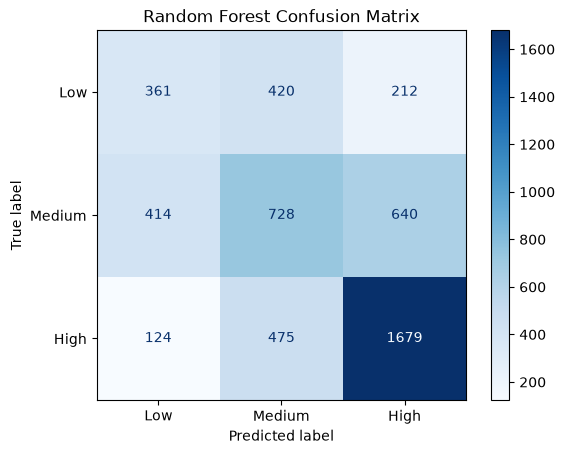

In [72]:
# visualizing confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Random Forest Confusion Matrix")
plt.show()


## 2. XGBoost

In [73]:
import xgboost as xgb

In [74]:
# Train the xgboost model

from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# Convert severity labels into numeric labels for XGBoost
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Initialize the Gradient Boosting model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6, # limit of every tree
    learning_rate=0.1,
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_combined, y_train_encoded)

# Predict severity
y_pred_xgb_encoded = xgb_model.predict(X_test_combined)

# Convert predictions back to severity labels
y_pred_xgb = label_encoder.inverse_transform(
    y_pred_xgb_encoded.astype(int)
)

print("XGBoost training complete.")
print("Number of predictions:", len(y_pred_xgb))


XGBoost training complete.
Number of predictions: 5053


In [75]:
# Evaluate the model

# Evaluate accuracy
print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    labels=['High', 'Low', 'Medium', ],
    zero_division=0
))

# Numerical confusion matrix
cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb,
    labels=['Low', 'Medium', 'High']
)

print("\nConfusion Matrix:")
print("Rows = Actual classes; Columns = Predicted classes")
print("Class order: Low, Medium, High")
print(cm_xgb)


XGBoost Accuracy: 0.565604591331882

Classification Report:
              precision    recall  f1-score   support

        High       0.66      0.76      0.71      2278
         Low       0.45      0.31      0.37       993
      Medium       0.46      0.46      0.46      1782

    accuracy                           0.57      5053
   macro avg       0.53      0.51      0.51      5053
weighted avg       0.55      0.57      0.55      5053


Confusion Matrix:
Rows = Actual classes; Columns = Predicted classes
Class order: Low, Medium, High
[[ 306  468  219]
 [ 304  821  657]
 [  63  484 1731]]


- Accuracy of 56.57%, meaning the model classifies appropriately 56 out of every 100 test claim.
- High severity: Recall is 76%, meaning the model identifies approximately 76% of genuinely High-severity claims and misses about 24%.
- Low severity: Recall is only 31%, so the model struggles to identify this class correctly.
- Medium severity: Recall is 46%, meaning many Medium claims are being assigned another category.

Confusion Matrix
- Low severity: Correctly classified 306 of 993 claims (30.8%). The model often predicts these as Medium.
- Medium severity: Correctly classified 821 of 1,782 claims (46.1%). However, 657 are incorrectly classified as High.
- High severity: Correctly classified 1,731 of 2,278 claims (76.0%). Only 63 are incorrectly classified as Low, while 484 are classified as Medium.

**Note:** XGBoost is the better performing model especially while identifying high severity claims

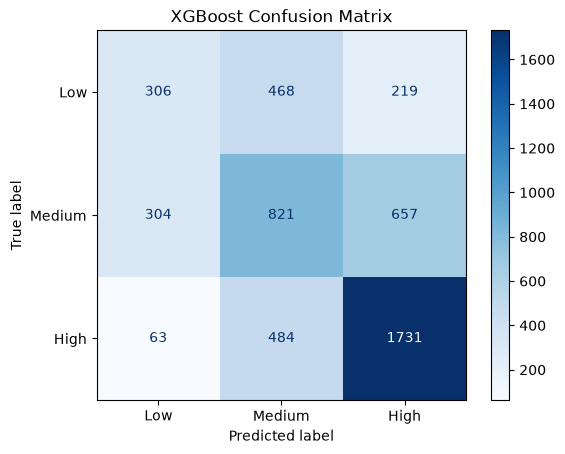

In [76]:
# confusion matrix visualization

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("XGBoost Confusion Matrix")
plt.show()


# 3. Multilayer Perceptron — MLP

## Feature Scaling 
- Scaling helps the neural network learn effectively when features have very different numerical ranges
- using Standardscaler on structured features because MLP neural networks generally perform better when numerical features are standardized to have a mean of 0 and a standard deviation of 1, helping prevent features with larger numerical ranges from dominating the learning process.

In [77]:

from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack, csr_matrix

# Scale the structured features using training data only
scaler = StandardScaler()

X_train_structured_scaled = scaler.fit_transform(
    X_train_no_estimate
)

X_test_structured_scaled = scaler.transform(
    X_test_no_estimate
)

# Combine scaled structured features with TF-IDF features
X_train_mlp = hstack(
    [csr_matrix(X_train_structured_scaled), X_train_text],
    format='csr'
)

X_test_mlp = hstack(
    [csr_matrix(X_test_structured_scaled), X_test_text],
    format='csr'
)

print("MLP training shape:", X_train_mlp.shape)
print("MLP testing shape:", X_test_mlp.shape)


MLP training shape: (16615, 488)
MLP testing shape: (5053, 488)


In [123]:
# Train MLP neural network
from sklearn.neural_network import MLPClassifier

# Initialize the MLP neural network
mlp_model = MLPClassifier(
    hidden_layer_sizes=(100, 50), # tow hidden layers with 100 neurons and 50 neurons
    activation='relu', # help network learn non-linear patterns
    solver='adam', # adjusts the network's weights during training
    max_iter=300,
    early_stopping=True, # stop training if validation performance stops improving
    random_state=42
)

# Train the model
mlp_model.fit(X_train_mlp, y_train)

# Predict claim severity
y_pred_mlp = mlp_model.predict(X_test_mlp)

print("MLP training complete.")
print("Number of predictions:", len(y_pred_mlp))


MLP training complete.
Number of predictions: 5053


In [124]:
# Evaluate the MLP model

# Calculate accuracy
print("MLP Accuracy:", accuracy_score(y_test, y_pred_mlp))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_mlp,
    labels=['High','Low', 'Medium', ],
    zero_division=0
))

# Numerical confusion matrix
cm_mlp = confusion_matrix(
    y_test,
    y_pred_mlp,
    labels=['Low', 'Medium', 'High']
)

print("\nConfusion Matrix:")
print("Rows = Actual classes; Columns = Predicted classes")
print("Class order: Low, Medium, High")
print(cm_mlp)


MLP Accuracy: 0.5713437561844449

Classification Report:
              precision    recall  f1-score   support

        High       0.63      0.84      0.72      2278
         Low       0.46      0.31      0.37       993
      Medium       0.50      0.37      0.42      1782

    accuracy                           0.57      5053
   macro avg       0.53      0.51      0.50      5053
weighted avg       0.55      0.57      0.55      5053


Confusion Matrix:
Rows = Actual classes; Columns = Predicted classes
Class order: Low, Medium, High
[[ 309  385  299]
 [ 297  654  831]
 [  72  282 1924]]


- Accuracy of 57.13%, meaning the model classifies appropriately 57 out of every 100 test claim.
- High severity: Recall is 84%, meaning the model identifies approximately 84% of genuinely High-severity claims and misses about 16%.
- Low severity: Recall is only 31%, so the model struggles to identify this class correctly.
- Medium severity: Recall is 37%, meaning many Medium claims are being assigned another category.

Confusion Matrix
- Low Severity: The model correctly identified 309 Low-severity claims. It incorrectly classified 385 as Medium and 299 as High. This is the weakest class in terms of recall.
- Medium Severity: The model correctly identified 654 Medium-severity claims. However, 297 were classified as Low and 831 as High.
- High Severity: The model correctly identified 1,924 High-severity claims. It misclassified 282 as Medium and 72 as Low. This is the strongest class in terms of recall.

**Note:** The MLP is effective at identifying High-cost claims, which could be useful for prioritising claims for review. However, its weaker performance on Low and Medium claims means it should not be treated as a reliable standalone triage system.

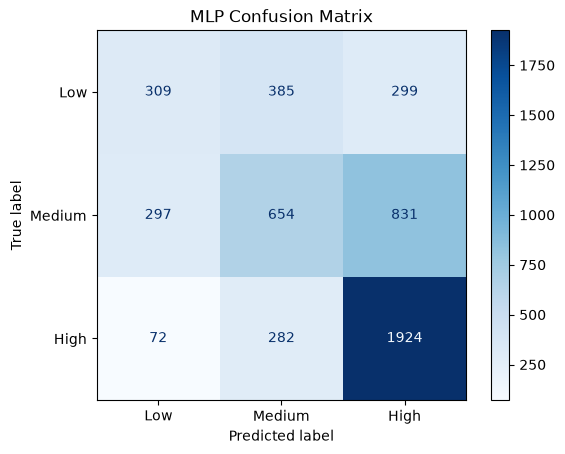

In [80]:
# confusion matrix visualization
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("MLP Confusion Matrix")
plt.show()


### Final Model Comparison

In [81]:
from sklearn.metrics import accuracy_score, f1_score, recall_score

# Compare the three models
models = {
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'MLP Neural Network': y_pred_mlp
}

results = []

for model_name, y_pred in models.items():
    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Low Recall': recall_score(
            y_test, y_pred, labels=['Low'], average=None
        )[0],
        'Medium Recall': recall_score(
            y_test, y_pred, labels=['Medium'], average=None
        )[0],
        'High Recall': recall_score(
            y_test, y_pred, labels=['High'], average=None
        )[0],
        'Macro F1-Score': f1_score(
            y_test, y_pred, average='macro'
        )
    })

comparison_df = pd.DataFrame(results)

# Display scores as percentages
comparison_df[['Accuracy', 'Low Recall', 'Medium Recall',
               'High Recall', 'Macro F1-Score']] *= 100

comparison_df = comparison_df.round(2)

comparison_df

,Model,Accuracy,Low Recall,Medium Recall,High Recall,Macro F1-Score
0,Random Forest,54.78,36.35,40.85,73.71,50.25
1,XGBoost,56.56,30.82,46.07,75.99,51.26
2,MLP Neural Network,57.13,31.12,36.70,84.46,50.43


MLP Neural Network is generally the best at detecting high severity claims, although it still struggles to distinguish Low and Medium claims, which is the main priority in categorizing an insurance claim. But it still cant be used on its own.

# **Feature Importance**
> - It indicates how much a feature contributes to the Random Forest's predictive decisions; it does not establish that the feature causes higher claim severity.

In [82]:
# Combine structured feature names and TF-IDF keyword names
feature_names = (
    X_train_no_estimate.columns.tolist()
    + tfidf.get_feature_names_out().tolist()
)

# Extract feature importance from the trained Random Forest
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

# Display the 15 most important features
importance_df = importance_df.sort_values(
    by='Importance', ascending=False
)

importance_df.head(20)

,Feature,Importance
3,WeeklyRate,0.055560
2,Age,0.047873
0,ReportingDelay,0.041903
8,AccidentYear,0.037839
1,AccidentHour,0.034748
4,HoursWorkedPerWeek,0.033874
9,AccidentMonth,0.033545
400,strain,0.032184
42,back,0.029311
10,AccidentDayOfWeek,0.028196


- WeeklyRate (0.0556): The most important feature, suggesting that the employee's weekly pay contributes to severity predictions.
- Age (0.0479): The employee's age helps the model distinguish between severity categories.
- ReportingDelay (0.0419): The time taken to report a claim contributes to the predictions.
- AccidentYear (0.0378) and AccidentMonth (0.0335): The timing of the accident provides useful predictive information.
- AccidentHour (0.0347) and HoursWorkedPerWeek (0.0339): The time of the accident and working hours also influence predictions.
- Claim-description keywords: Terms such as strain, back, lacer, left, strike, right and shoulder indicate that descriptions of injuries and accident circumstances contribute to the model's predictions thus showing that NLP adds useful information beyond the structured data.

# **Dimensionality Reduction**

# 1. TruncatedSVD

In [83]:
print("Training data shape:", X_train_combined.shape)
print("Testing data shape:", X_test_combined.shape)
print("Training data type:", type(X_train_combined))

Training data shape: (16615, 488)
Testing data shape: (5053, 488)
Training data type: <class 'scipy.sparse._csr.csr_matrix'>


data is stored as a sparse matrix, which is efficient for TF-IDF features. Because of this, TruncatedSVD will be used rather than ordinary PCA. It works directly with sparse matrices and serves a similar dimensionality-reduction purpose for the combined data.

In [84]:
# Fit TruncatedSVD
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=200, random_state=42) # 200 components since data has 488 features

X_train_reduced = svd.fit_transform(X_train_combined)

print("Original training shape:", X_train_combined.shape)
print("Reduced training shape:", X_train_reduced.shape)
print("Explained variance ratio:", svd.explained_variance_ratio_.sum())

Original training shape: (16615, 488)
Reduced training shape: (16615, 200)
Explained variance ratio: 0.9999995742888483


Training data has been reduced from 488 features to 200 components.
However, the explained variance ratio of 0.9999996 is unusually high for TF-IDF data. This can happen because TruncatedSVD's explained_variance_ratio_ measures variance relative to the observed variance of the input.

In [85]:
# Transform the testing data
X_test_reduced = svd.transform(X_test_combined)

print("Reduced training shape:", X_train_reduced.shape)
print("Reduced testing shape:", X_test_reduced.shape)

Reduced training shape: (16615, 200)
Reduced testing shape: (5053, 200)


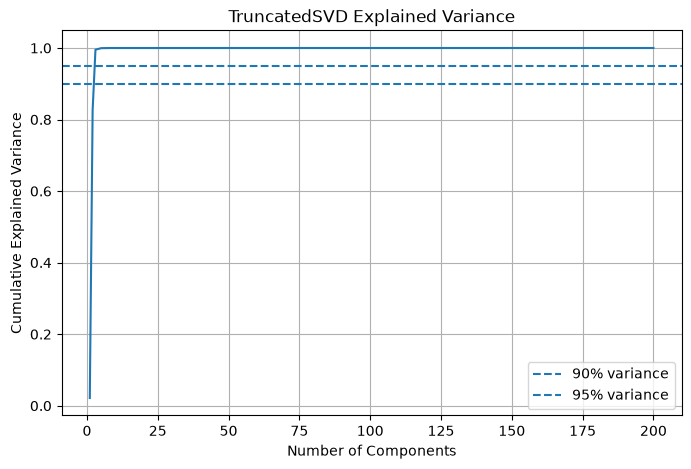

Variance explained by 200 components: 1.0


In [86]:
# Check explained variance
cumulative_variance = np.cumsum(svd.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(y=0.90, linestyle='--', label='90% variance')
plt.axhline(y=0.95, linestyle='--', label='95% variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('TruncatedSVD Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

print("Variance explained by 200 components:",
      round(cumulative_variance[-1], 4))

The curve shoots up almost vertically at the beginning meaning that nearly 100% of the variance is captured by the first few components and the remaining components contribute almost zero new information.

The dotted lines mark the thresholds for capturing 90 and 95 percent of the variance.

Recommendation: reduce dataset from 200 features down to 2-5 components, which will sigificantly speed up the models training and because the first few components capture the variance, the models accuracy will remain virtually unchanged despite using less data.

In [87]:
# Finding how many components reach 90% and 95%
cumulative_variance = np.cumsum(svd.explained_variance_ratio_)

components_90 = np.argmax(cumulative_variance >= 0.90) + 1
components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Components needed for 90% variance:", components_90)
print("Components needed for 95% variance:", components_95)

print("Variance with first 5 components:",
      round(cumulative_variance[4], 6))

print("Variance with first 10 components:",
      round(cumulative_variance[9], 6))

Components needed for 90% variance: 3
Components needed for 95% variance: 3
Variance with first 5 components: 0.999534
Variance with first 10 components: 0.999963


In [88]:
# Reduce the data to 3 components

from sklearn.decomposition import TruncatedSVD

svd_3 = TruncatedSVD(n_components=3, random_state=42)

X_train_svd3 = svd_3.fit_transform(X_train_combined)
X_test_svd3 = svd_3.transform(X_test_combined)

print("Training shape:", X_train_svd3.shape)
print("Testing shape:", X_test_svd3.shape)
print("Explained variance:",
      round(svd_3.explained_variance_ratio_.sum(), 4))

Training shape: (16615, 3)
Testing shape: (5053, 3)
Explained variance: 0.9952


# 2. t-SNE
- t-SNE reduces THE data to 2 dimensions to visualise how the insurance claims are distributed. t-SNE rearranges the data to show local similarities, so distances between separate groups should not be interpreted as reliable measures of their original separation.

In [89]:

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Use a sample of the training data
sample_size = 3000
rng = 42

sample_indices = np.random.RandomState(rng).choice(
    X_train_svd3.shape[0],
    size=sample_size,
    replace=False
)

X_tsne_input = X_train_svd3[sample_indices]

# Apply t-SNE to reduce the data to 2 dimensions
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_tsne_input)

print("Original sampled shape:", X_tsne_input.shape)
print("t-SNE shape:", X_tsne.shape)


Original sampled shape: (3000, 3)
t-SNE shape: (3000, 2)


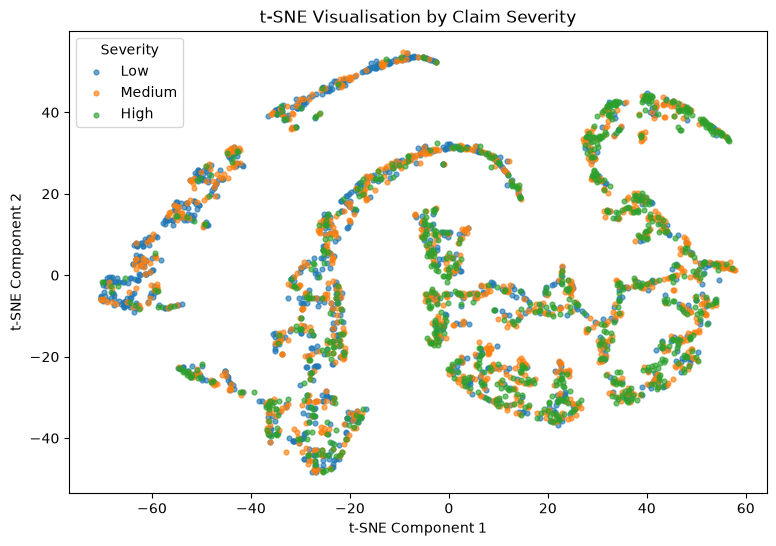

In [90]:
# plot the results

# Get the severity labels for the same sampled claims
y_tsne = y_train.iloc[sample_indices]

plt.figure(figsize=(9, 6))

for severity in ["Low", "Medium", "High"]:
    mask = y_tsne.to_numpy() == severity

    plt.scatter(
        X_tsne[mask, 0],
        X_tsne[mask, 1],
        label=severity,
        s=12,
        alpha=0.65
    )

plt.title("t-SNE Visualisation by Claim Severity")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend(title="Severity")
plt.show()


The t-SNE visualisation shows substantial overlap between Low, Medium and High severity claims, with no clearly separated groups for the three classes. This suggests that claims with different severity levels share similarities in the reduced feature space.

However, t-SNE is an exploratory visualisation technique and the overlap does not necessarily mean that the original features lack predictive information. The ability to distinguish severity levels must be assessed using classification metrics.

**Conclusion:** The visualisation does not reveal clear severity-based groupings, supporting further investigation through clustering techniques and evaluation of classification performance.

# 3. UMAP

In [91]:
import umap

# Use the same sample as the t-SNE visualisation
X_umap_input = X_train_svd3[sample_indices]

# Apply UMAP to reduce to 2 dimensions
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

X_umap = umap_model.fit_transform(X_umap_input)

print("Original sampled shape:", X_umap_input.shape)
print("UMAP shape:", X_umap.shape)


c:\Users\User\OneDrive\Documents\Final_Capstone_Project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\User\OneDrive\Documents\Final_Capstone_Project\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Original sampled shape: (3000, 3)
UMAP shape: (3000, 2)


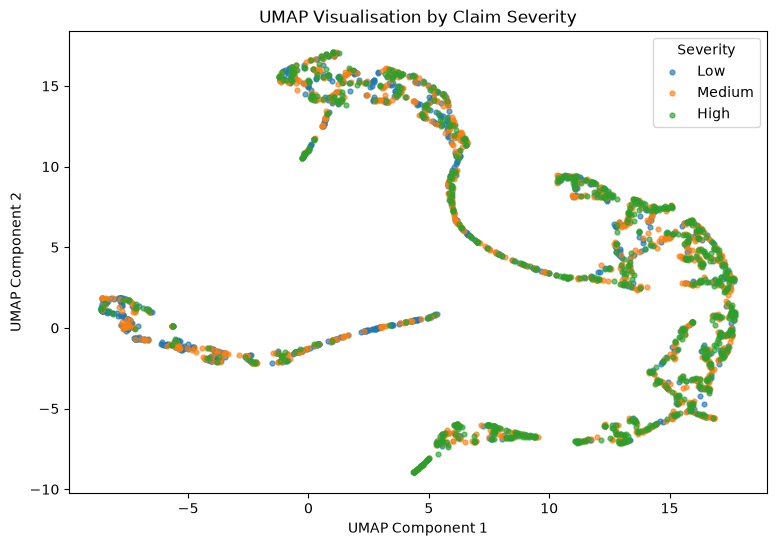

In [92]:
# visualizing

y_umap = y_train.iloc[sample_indices]

plt.figure(figsize=(9, 6))

for severity in ["Low", "Medium", "High"]:
    mask = y_umap.to_numpy() == severity

    plt.scatter(
        X_umap[mask, 0],
        X_umap[mask, 1],
        label=severity,
        s=12,
        alpha=0.65
    )

plt.title("UMAP Visualisation by Claim Severity")
plt.xlabel("UMAP Component 1")
plt.ylabel("UMAP Component 2")
plt.legend(title="Severity")
plt.show()



The UMAP visualisation reveals distinct branch-like structures and groupings within the insurance claims data, suggesting that the feature space contains underlying patterns or subgroups. However, Low, Medium, and High severity claims overlap substantially across these structures, with no clearly isolated groups corresponding to individual severity classes.

This suggests that the patterns captured by UMAP do not directly correspond to clear severity-based groupings. Although the features may contain useful information, severity prediction remains challenging because the classes are not clearly separated in this two-dimensional representation.

**Conclusion:** UMAP reveals underlying structures in the claims data, but these structures do not clearly distinguish severity levels. Classification performance must therefore be assessed using evaluation metrics rather than visualisation alone.

# **Clustering**

# 1. K-Means

In [93]:
# testing different numbers of clusters using silhouette score

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test between 2 and 6 clusters
k_values = range(2, 7) # 2, 3, 4, 5, 6
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_train_svd3)

    score = silhouette_score(
        X_train_svd3,
        cluster_labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_scores.append(score)
    print(f"k = {k}, Silhouette Score = {score:.4f}")


k = 2, Silhouette Score = 0.5561
k = 3, Silhouette Score = 0.5306
k = 4, Silhouette Score = 0.5388
k = 5, Silhouette Score = 0.5969
k = 6, Silhouette Score = 0.5984


k = 6 has the highest silhouette score of 0.5984, indicating that it has better-separated, more cohesive clusters.

In [94]:
# Fit K-Means with 6 clusters

from sklearn.cluster import KMeans

kmeans_final = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

# Fit clusters using training data only
train_clusters = kmeans_final.fit_predict(X_train_svd3)

# Examine cluster sizes
cluster_sizes = pd.Series(train_clusters).value_counts().sort_index()

print("Number of claims in each cluster:")
print(cluster_sizes)


Number of claims in each cluster:
0    3045
1    1628
2    6375
3    5475
4      28
5      64
Name: count, dtype: int64


In [95]:
# Examine severity distribution in each cluster
# check whether the clusters contain different proportions of Low, Medium, and High severity claims

# Combine the cluster assignments with the actual training labels
cluster_analysis = pd.DataFrame({
    'Cluster': train_clusters,
    'Severity': y_train.reset_index(drop=True)
})

# Show severity counts within each cluster
severity_counts = pd.crosstab(
    cluster_analysis['Cluster'],
    cluster_analysis['Severity']
)

print("Severity counts by cluster:")
display(severity_counts)

print("\nSeverity percentages within each cluster:")
display(
    pd.crosstab(
        cluster_analysis['Cluster'],
        cluster_analysis['Severity'],
        normalize='index'
    ).mul(100).round(2)
)


Severity counts by cluster:


Severity,High,Low,Medium
Cluster,,,
0,342,1860,843
1,810,305,513
2,1584,2591,2200
3,2084,1388,2003
4,17,2,9
5,36,12,16



Severity percentages within each cluster:


Severity,High,Low,Medium
Cluster,,,
0,11.23,61.08,27.68
1,49.75,18.73,31.51
2,24.85,40.64,34.51
3,38.06,25.35,36.58
4,60.71,7.14,32.14
5,56.25,18.75,25.00


- Cluster 0: Mostly Low severity (about 61.1%). This cluster is dominated by Low-cost claims.
- Cluster 1: Mostly High severity (about 49.8%). High is the largest category in this cluster.
- Cluster 2: A mixed cluster, with Low severity the largest category (about 40.6%).
- Cluster 3: Mostly High severity (about 38.1%), although Medium and Low claims are also well represented.
- Cluster 4: Very small, with 17 High claims out of 28. Interpret cautiously because the group is tiny.
- Cluster 5: Mostly High severity (36 out of 64, or 56.3%), but this group is also small.

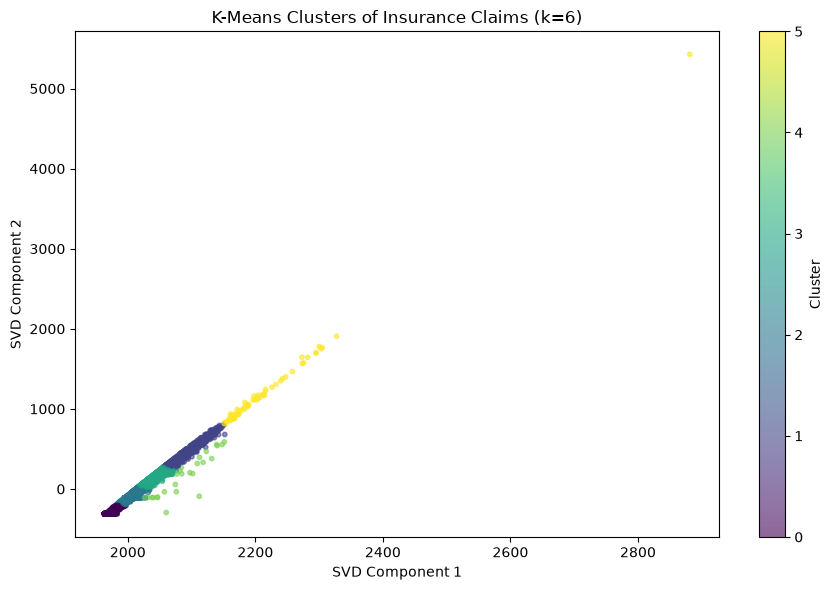

In [96]:
# Visualizing the clusters

plt.figure(figsize=(9, 6))

plt.scatter(
    X_train_svd3[:, 0],
    X_train_svd3[:, 1],
    c=train_clusters,
    cmap='viridis',
    s=10,
    alpha=0.6
)

plt.xlabel('SVD Component 1')
plt.ylabel('SVD Component 2')
plt.title('K-Means Clusters of Insurance Claims (k=6)')
plt.colorbar(label='Cluster')
plt.tight_layout()
plt.show()


- **Continuous Data Distribution:** The data points form a tight, continuous sweeping line rather than distinct, isolated clusters, suggesting that claims vary gradually across the reduced feature space.

- **Cluster Formation:** K-Means divided the continuous pattern into six clusters. The groups appear as consecutive segments along the line rather than clearly separated groups.

- **Small Clusters:** Clusters 4 and 5 contain only 28 and 64 claims, respectively. These small groups may represent less common patterns in the data, but further investigation would be needed before interpreting them as anomalies.

- **Relationship with Severity:** The severity distribution varies across clusters. Cluster 0 contains predominantly Low-severity claims, while Cluster 1 contains the largest proportion of High-severity claims. However, no cluster corresponds exclusively to one severity category.

- **Visualisation Limitation:** The scatter plot displays only the first two SVD components, whereas K-Means used all three components. Therefore, the two-dimensional plot may not fully represent the separation between clusters.

**Conclusion:** K-Means identified groups with different severity distributions, but the continuous visual pattern suggests that the claims do not naturally form six clearly isolated groups in the displayed feature space. Clustering therefore provides exploratory insights into claim patterns rather than definitive severity classifications.

# 2. GMM (Gaussian Mixture Model)

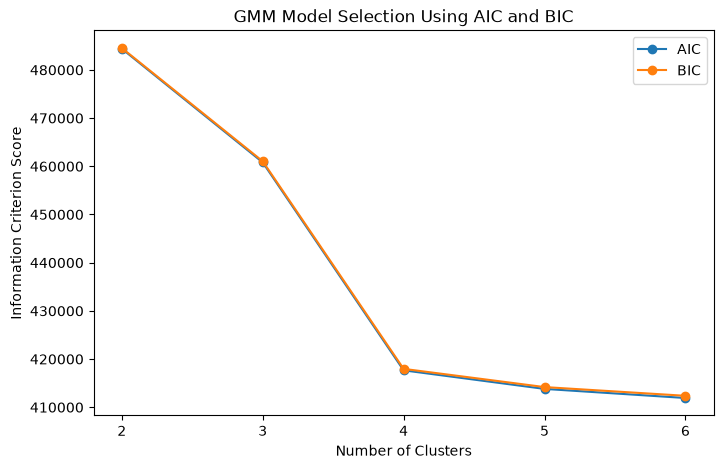

In [97]:
# Find best number of clusters

from sklearn.mixture import GaussianMixture

cluster_range = range(2, 7)
aic_scores = []
bic_scores = []

for k in cluster_range:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
        n_init=3
    )
    gmm.fit(X_train_svd3)

    aic_scores.append(gmm.aic(X_train_svd3))
    bic_scores.append(gmm.bic(X_train_svd3))

plt.figure(figsize=(8, 5))
plt.plot(list(cluster_range), aic_scores, marker="o", label="AIC")
plt.plot(list(cluster_range), bic_scores, marker="o", label="BIC")

plt.xlabel("Number of Clusters")
plt.ylabel("Information Criterion Score")
plt.title("GMM Model Selection Using AIC and BIC")
plt.xticks(list(cluster_range))
plt.legend()
plt.show()


Both AIC and BIC decrease as the number of GMM clusters increases, although the improvement becomes smaller after four clusters.
- 2 to 4 clusters: The scores decrease substantially, suggesting improved model fit.
- 4 to 5 clusters: The improvement becomes smaller.
- 5 to 6 clusters: The scores decrease again, but the improvement appears more modest.

In [98]:
# Fit GMM with 6 clusters

from sklearn.mixture import GaussianMixture

gmm_final = GaussianMixture(
    n_components=6,
    random_state=42,
    n_init=3
)

gmm_clusters = gmm_final.fit_predict(X_train_svd3)

gmm_cluster_sizes = pd.Series(gmm_clusters).value_counts().sort_index()

print("GMM Cluster Sizes:")
print(gmm_cluster_sizes)


GMM Cluster Sizes:
0    2738
1    3833
2    2629
3    1090
4     175
5    6150
Name: count, dtype: int64


- Cluster 5 is the largest, containing approximately 37% of the training claims.
- Cluster 4 is the smallest, containing approximately 1.1%.
- The clusters are unevenly sized, suggesting that the fitted Gaussian distributions represent different portions of the feature space.

In [99]:
# Comparing cluusters with severity

# Combine cluster assignments with the actual severity labels
gmm_results = pd.DataFrame({
    "Cluster": gmm_clusters,
    "Severity": y_train.reset_index(drop=True)
})

# Show severity counts within each cluster
gmm_severity_counts = pd.crosstab(
    gmm_results["Cluster"],
    gmm_results["Severity"]
)

print("Severity Distribution Across GMM Clusters:")
print(gmm_severity_counts)


Severity Distribution Across GMM Clusters:
Severity  High   Low  Medium
Cluster                     
0         1080   685     973
1          782  1742    1309
2          230  1686     713
3          383   349     358
4           84    38      53
5         2314  1658    2178


The GMM algorithm identified six clusters with varying sizes and severity distributions. Cluster 2 was predominantly composed of Low-severity claims, while Cluster 1 also contained more Low-severity claims than the other categories. Clusters 0, 4 and 5 had High severity as their most frequent category, whereas Cluster 3 showed a relatively balanced distribution.

These findings indicate that the reduced feature space contains groups with different severity compositions. However, no cluster consisted exclusively of one severity class. Furthermore, Cluster 4 was considerably smaller than the others and may warrant further investigation.

**Conclusion:** GMM identified differences in the composition of insurance claims, but the clusters do not directly correspond to the severity classes. Clustering is therefore useful for exploratory analysis rather than as a replacement for supervised severity classification.

# 3. DBSCAN

In [100]:
# Apply DBSCAN

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Scale the SVD components for DBSCAN
dbscan_scaler = StandardScaler()
X_train_dbscan = dbscan_scaler.fit_transform(X_train_svd3)

# Apply DBSCAN
dbscan = DBSCAN(
    eps=0.5,
    min_samples=10
)

dbscan_clusters = dbscan.fit_predict(X_train_dbscan)

# Count points in each cluster, including noise (-1)
dbscan_cluster_sizes = pd.Series(dbscan_clusters).value_counts().sort_index()

print("DBSCAN Cluster Sizes:")
print(dbscan_cluster_sizes)
print("\nNumber of clusters (excluding noise):",
      len(set(dbscan_clusters)) - (1 if -1 in dbscan_clusters else 0))
print("Number of noise points:", (dbscan_clusters == -1).sum())


DBSCAN Cluster Sizes:
-1      121
 0    16484
 1       10
Name: count, dtype: int64

Number of clusters (excluding noise): 2
Number of noise points: 121


- Cluster 0: Almost all claims belong to one large, dense group.
- Cluster 1: Only 10 claims form a small second cluster.
- Cluster - (Noise points): identified 121 claims that did not meet its density requirements.

In [101]:
# check severity of the noise points

dbscan_results = pd.DataFrame({
    "Cluster": dbscan_clusters,
    "Severity": y_train.reset_index(drop=True)
})

print("Severity Distribution Across DBSCAN Groups:")
print(pd.crosstab(
    dbscan_results["Cluster"],
    dbscan_results["Severity"]
))


Severity Distribution Across DBSCAN Groups:
Severity  High   Low  Medium
Cluster                     
-1          65    18      38
 0        4800  6140    5544
 1           8     0       2


DBSCAN identified two clusters and 121 noise points using the selected parameters. The majority of claims belonged to Cluster 0, indicating that the data was largely treated as one dense group. Cluster 1 contained only ten claims, while the noise points represented approximately 0.73% of the training data.

The noise points contained a higher proportion of High-severity claims than the overall training dataset. However, DBSCAN identifies noise based on feature-space density, not claim severity or fraud status. The small second cluster and dominant main cluster also indicate that the results may be sensitive to the selected parameters.

**Conclusion:** DBSCAN identified a small set of density-based noise points, some of which were High severity. Further parameter testing would be needed to determine whether these patterns are robust.

## Testing different parameter combinations

In [102]:
results = []

eps_values = [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
min_samples_values = [5, 10, 15, 20]

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan.fit_predict(X_train_dbscan)

        n_clusters = len(set(labels) - {-1})
        n_noise = (labels == -1).sum()

        results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": n_clusters,
            "noise_points": n_noise,
            "noise_percent": round(
                n_noise / len(labels) * 100, 2
            )
        })

dbscan_results_table = pd.DataFrame(results)

print(dbscan_results_table.to_string(index=False))


 eps  min_samples  clusters  noise_points  noise_percent
 0.1            5        19           778           4.68
 0.1           10        10          1219           7.34
 0.1           15         6          1604           9.65
 0.1           20         4          1870          11.25
 0.2            5         7           248           1.49
 0.2           10         4           413           2.49
 0.2           15         1           524           3.15
 0.2           20         3           583           3.51
 0.3            5         3           160           0.96
 0.3           10         3           227           1.37
 0.3           15         1           317           1.91
 0.3           20         1           372           2.24
 0.5            5         3            84           0.51
 0.5           10         2           121           0.73
 0.5           15         2           148           0.89
 0.5           20         1           187           1.13
 0.7            5         2    

- 0.1, 5: Finds many small clusters and more noise.
- 0.2, 5: Finds seven clusters with relatively few noise points. This is a reasonable starting candidate.
- 0.3, 10: Finds three clusters, also with relatively few noise points.

In [103]:
# Trying eps=0.2, min_samples=5

dbscan_tuned = DBSCAN(
    eps=0.2,
    min_samples=5
)

dbscan_tuned_clusters = dbscan_tuned.fit_predict(
    X_train_dbscan
)

print("Tuned DBSCAN Cluster Sizes:")
print(
    pd.Series(dbscan_tuned_clusters)
    .value_counts()
    .sort_index()
)

print(
    "\nNumber of clusters:",
    len(set(dbscan_tuned_clusters) - {-1})
)

print(
    "Number of noise points:",
    (dbscan_tuned_clusters == -1).sum()
)


Tuned DBSCAN Cluster Sizes:
-1      248
 0    16319
 1        6
 2       16
 3       10
 4        5
 5        6
 6        5
Name: count, dtype: int64

Number of clusters: 7
Number of noise points: 248


One cluster (0) still contains almost all the claims while the others are still very small

In [104]:
# Checking severity distribution

dbscan_tuned_results = pd.DataFrame({
    "Cluster": dbscan_tuned_clusters,
    "Severity": y_train.reset_index(drop=True)
})

print("Severity Distribution Across Tuned DBSCAN Groups:")
print(
    pd.crosstab(
        dbscan_tuned_results["Cluster"],
        dbscan_tuned_results["Severity"]
    )
)


Severity Distribution Across Tuned DBSCAN Groups:
Severity  High   Low  Medium
Cluster                     
-1         129    44      75
 0        4724  6101    5494
 1           2     1       3
 2           8     2       6
 3           4     3       3
 4           3     1       1
 5           2     3       1
 6           1     3       1


After adjusting the DBSCAN parameters to `eps=0.2` and `min_samples=5`, the model identified seven clusters and 248 noise points. However, Cluster 0 contained approximately 98.2% of the training claims, while the remaining clusters were very small.

The noise points contained a higher proportion of High-severity claims (approximately 52%) than the overall training dataset. This suggests a possible association between severity and the density-based structure of the reduced feature space. Nevertheless, DBSCAN identifies noise based on density rather than severity, and the observed relationship does not establish causation or indicate fraud.

**Conclusion:** Parameter tuning increased the number of identified clusters, but DBSCAN continued to produce one dominant cluster and several very small groups. The results provide limited evidence of distinct density-based groupings in the current representation.

# **Modelling**

# 1. Random Forest 2.0

One caution: Three SVD components compress 488 features very aggressively. The model may perform worse because some information useful for predicting severity could be lost. 

In [105]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

rf_svd3 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_svd3.fit(X_train_svd3, y_train)

y_pred_rf_svd3 = rf_svd3.predict(X_test_svd3)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf_svd3), 4))
print("Macro F1-score:", round(f1_score(y_test, y_pred_rf_svd3, average='macro'), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf_svd3))

Accuracy: 0.4368
Macro F1-score: 0.3866

Classification Report:

              precision    recall  f1-score   support

        High       0.53      0.59      0.56      2278
         Low       0.27      0.20      0.23       993
      Medium       0.38      0.38      0.38      1782

    accuracy                           0.44      5053
   macro avg       0.39      0.39      0.39      5053
weighted avg       0.42      0.44      0.43      5053



The reduced model showed lower recall for all three severity classes, particularly High severity, which had a recall of 59% and previously had 74%. These results suggest that compressing the original 488 features into only three components removed information important for predicting claim severity.

**Conclusion:** The three-component SVD representation was useful for exploratory visualisation and clustering, but it did not improve Random Forest classification performance. A representation with more components should be tested before concluding that dimensionality reduction is unsuitable for classification.

## Comparing different numbers of SVD components

In [106]:

from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, f1_score, accuracy_score

# Number of SVD components to compare
component_counts = [10, 20, 38, 50, 100]
results = []

for n in component_counts:
    # Reduce dimensionality using training data only
    svd = TruncatedSVD(n_components=n, random_state=42)
    X_train_reduced = svd.fit_transform(X_train_combined)
    X_test_reduced = svd.transform(X_test_combined)

    # Train Random Forest
    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train_reduced, y_train)

    # Predict test labels
    y_pred = rf.predict(X_test_reduced)

    # Record evaluation metrics
    results.append({
        "SVD Components": n,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro"
        ),
        "Low Recall": recall_score(
            y_test, y_pred, labels=["Low"],
            average=None
        )[0],
        "Medium Recall": recall_score(
            y_test, y_pred, labels=["Medium"],
            average=None
        )[0],
        "High Recall": recall_score(
            y_test, y_pred, labels=["High"],
            average=None
        )[0]
    })

# Display results, rounded for readability
results_df = pd.DataFrame(results).set_index("SVD Components")
print(results_df.round(4))


                Accuracy  Macro Recall  Macro F1  Low Recall  Medium Recall  \
SVD Components                                                                
10                0.4799        0.4100    0.4030      0.1501         0.3715   
20                0.5227        0.4685    0.4690      0.2810         0.4029   
38                0.5442        0.4996    0.5000      0.3545         0.4209   
50                0.5357        0.4917    0.4923      0.3505         0.4085   
100               0.5205        0.4824    0.4812      0.3706         0.3838   

                High Recall  
SVD Components               
10                   0.7085  
20                   0.7217  
38                   0.7234  
50                   0.7160  
100                  0.6927  


- 10 components: Lowest performance, with a macro F1-score of 0.4030 and macro recall of 41.00%, suggesting too much useful information was lost.
- 20 components: Performance improved, reaching a macro F1-score of 0.4690 and macro recall of 46.85%.
- 38 components: Best overall performance, achieving the highest accuracy (54.42%), macro F1-score (0.5000), and macro recall (49.96%).
- 50 components: Performance declined slightly compared with 38 components.
- 100 components: Did not improve overall performance; High-severity recall also fell to 69.27%.
Conclusion: The 38-component model is the strongest option among those tested because it achieved the best overall balance of recall and F1-score. However, Low-severity recall remained weak at 35.45%, meaning the model missed nearly two-thirds of actual Low-severity claims.

## 38-component representation (38 SVD)

In [107]:

from sklearn.decomposition import TruncatedSVD

svd_38 = TruncatedSVD(
    n_components=38,
    random_state=42
)

X_train_svd38 = svd_38.fit_transform(X_train_combined)
X_test_svd38 = svd_38.transform(X_test_combined)

print("Training shape:", X_train_svd38.shape)
print("Testing shape:", X_test_svd38.shape)
print(
    "Total explained variance:",
    round(svd_38.explained_variance_ratio_.sum(), 4)
)


Training shape: (16615, 38)
Testing shape: (5053, 38)
Total explained variance: 1.0


In [108]:
# Train and evaluate 

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

rf_svd38 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_svd38.fit(X_train_svd38, y_train)

y_pred_rf_svd38 = rf_svd38.predict(X_test_svd38)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf_svd38), 4))
print(
    "Macro F1-score:",
    round(f1_score(y_test, y_pred_rf_svd38, average="macro"), 4)
)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf_svd38))


Accuracy: 0.5442
Macro F1-score: 0.5

Classification Report:

              precision    recall  f1-score   support

        High       0.66      0.72      0.69      2278
         Low       0.40      0.35      0.38       993
      Medium       0.45      0.42      0.43      1782

    accuracy                           0.54      5053
   macro avg       0.50      0.50      0.50      5053
weighted avg       0.53      0.54      0.54      5053




The original Random Forest model, trained using all 488 features, achieved recall scores of approximately 74% for High-severity claims, 36% for Low-severity claims, and 41% for Medium-severity claims.

The model trained using three SVD components performed worse, with recall scores of 59% for High, 20% for Low, and 38% for Medium severity. This indicates that reducing the features to only three components resulted in a loss of information useful for identifying claims in each severity class.

Using 38 SVD components improved recall to 72% for High, 35% for Low, and 42% for Medium severity. These results were much closer to the original model, although recall for High severity remained slightly lower.

**Conclusion:** The original 488-feature model achieved the highest recall for High-severity claims, while the 38-component model achieved slightly higher recall for Medium-severity claims. Both models performed considerably better than the three-component model. Low-severity claims remained the most difficult to identify across all three models.

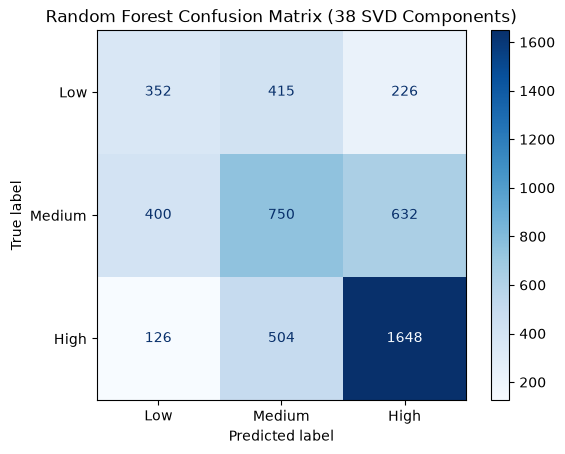

In [109]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_rf_svd38,
    labels=["Low", "Medium", "High"]
)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest Confusion Matrix (38 SVD Components)")
plt.show()


- Low severity: The model correctly identified 352 of 993 Low-severity claims. It misclassified 415 as Medium and 226 as High.
- Medium severity: It correctly identified 750 of 1,782 claims. It misclassified 400 as Low and 632 as High.
- High severity: It correctly identified 1,648 of 2,278 claims. It misclassified 504 as Medium and 126 as Low.

# 2. XGBoost 2.0

In [110]:

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Train XGBoost using 38 SVD components
xgb_svd38 = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="mlogloss"
)

xgb_svd38.fit(X_train_svd38, y_train_encoded)

# Make predictions
y_pred_xgb_svd38_encoded = xgb_svd38.predict(X_test_svd38)

# Convert predictions back to severity labels
y_pred_xgb_svd38 = label_encoder.inverse_transform(
    y_pred_xgb_svd38_encoded.astype(int)
)

# Evaluate the model
print("Accuracy:", round(accuracy_score(y_test, y_pred_xgb_svd38), 4))
print("Macro F1-score:", round(f1_score(
    y_test, y_pred_xgb_svd38, average="macro"
), 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_xgb_svd38))


Accuracy: 0.5314
Macro F1-score: 0.495

Classification Report:

              precision    recall  f1-score   support

        High       0.65      0.68      0.67      2278
         Low       0.40      0.38      0.39       993
      Medium       0.44      0.42      0.43      1782

    accuracy                           0.53      5053
   macro avg       0.50      0.49      0.49      5053
weighted avg       0.53      0.53      0.53      5053



- High severity: Recall was 68%, meaning the model correctly identified 68% of actual High-severity claims.
- Low severity: Recall was 38%, the lowest-performing class, with 62% of actual Low-severity claims missed.
- Medium severity: Recall was 42%, meaning the model identified 42% of actual Medium-severity claims.
- Overall performance: Accuracy was 53.14%, with a macro F1-score of 0.495.

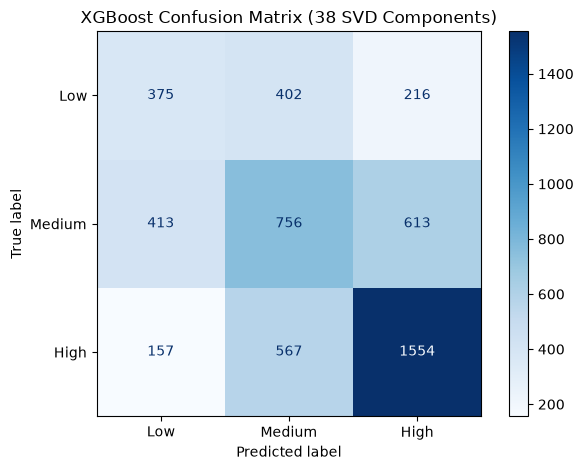

In [111]:
# Confusion Matrix

cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb_svd38,
    labels=["Low", "Medium", "High"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Low", "Medium", "High"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("XGBoost Confusion Matrix (38 SVD Components)")
plt.tight_layout()
plt.show()


- Low severity: Correctly identified 375 claims; most errors were classified as Medium (402).
- Medium severity: Correctly identified 756 claims; 613 were incorrectly classified as High.
- High severity: Correctly identified 1,554 claims; most errors were classified as Medium (567).

Conclusion: XGBoost identified High-severity claims best, with 68.2% recall. Medium recall was 42.4%, while Low recall was lowest at 37.8%. The model still struggles to distinguish between severity levels, especially Low and Medium claims.

# 3. Multilayer Perceptron — MLP 2.0

In [125]:
# Train MLP using 38 SVD components
mlp_svd38 = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    max_iter=300,
    random_state=42,
    early_stopping=True, 
    activation='relu',
    solver='adam'
)

mlp_svd38.fit(X_train_svd38, y_train)

# Make predictions
y_pred_mlp_svd38 = mlp_svd38.predict(X_test_svd38)

# Evaluate the model
print("Accuracy:", round(
    accuracy_score(y_test, y_pred_mlp_svd38), 4
))

print("Macro F1-score:", round(
    f1_score(y_test, y_pred_mlp_svd38, average="macro"), 4
))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_mlp_svd38))


Accuracy: 0.5047
Macro F1-score: 0.3857

Classification Report:

              precision    recall  f1-score   support

        High       0.61      0.82      0.70      2278
         Low       0.34      0.68      0.45       993
      Medium       0.50      0.00      0.00      1782

    accuracy                           0.50      5053
   macro avg       0.48      0.50      0.39      5053
weighted avg       0.52      0.50      0.41      5053



- High severity: Recall was 82%, the highest among the three classes. The model correctly identified most actual High-severity claims.
- Low severity: Recall was 68%, meaning it identified a much larger proportion of Low-severity claims than Random Forest or XGBoost.
- Medium severity: Recall was 0%. The model failed to correctly identify any Medium-severity claims, which is a serious weakness.
- Overall performance: Accuracy was 50.47%, while macro F1 was 0.3857, reflecting the poor performance on Medium severity.

In [119]:

from sklearn.metrics import confusion_matrix
import pandas as pd

cm_mlp = confusion_matrix(
    y_test,
    y_pred_mlp_svd38,
    labels=["Low", "Medium", "High"]
)

cm_mlp_df = pd.DataFrame(
    cm_mlp,
    index=["Actual Low", "Actual Medium", "Actual High"],
    columns=["Predicted Low", "Predicted Medium", "Predicted High"]
)

print(cm_mlp_df)


               Predicted Low  Predicted Medium  Predicted High
Actual Low               673                 0             320
Actual Medium            917                 3             862
Actual High              401                 3            1874


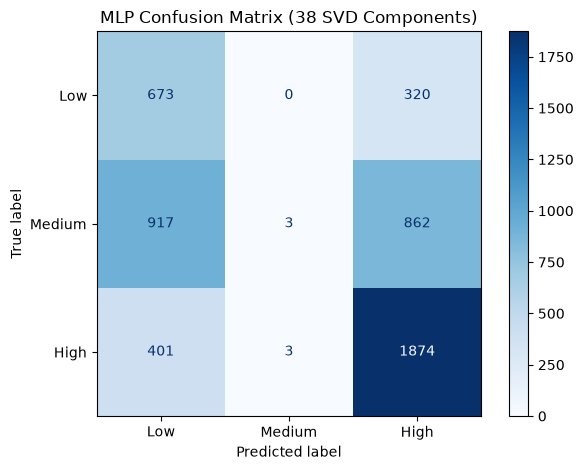

In [113]:
# Confusion Matrix
cm_mlp = confusion_matrix(
    y_test,
    y_pred_mlp_svd38,
    labels=["Low", "Medium", "High"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=["Low", "Medium", "High"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("MLP Confusion Matrix (38 SVD Components)")
plt.tight_layout()
plt.show()

- Low severity (673, 0, 320): Of 993 actual Low-severity claims, the model correctly classified 673 as Low, misclassified 0 as Medium, and misclassified 320 as High. Low recall is approximately 67.8%.
- Medium severity (917, 3, 862): Of 1,782 actual Medium-severity claims, only 3 were correctly classified as Medium. The model classified 917 as Low and 862 as High. Medium recall is approximately 0.2%, which rounds to 0% in the classification report.
- High severity (401, 3, 1,874): Of 2,278 actual High-severity claims, 1,874 were correctly classified as High, while 401 were classified as Low and 3 as Medium. High recall is approximately 82.3%.

The MLP strongly favors predicting Low or High severity and almost never predicts Medium. Although it identifies many High-severity claims, its failure to recognize Medium-severity claims makes its overall performance unbalanced. The model may have struggled to learn decision boundaries that distinguish medium claims from other classes after dimensionality reduction.

Conclusion: Dimensionality reduction is a plausible contributor to the MLP's failure to identify Medium claims. Considering the fact that the model predicted only six claims as Medium in total, despite having 1,782 actual Medium claims in the test set, is particularly telling.

## Comparison table 2.0

In [114]:
# Compare the three models
models = {
    'Random Forest': y_pred_rf_svd38,
    'XGBoost': y_pred_xgb_svd38,
    'MLP Neural Network': y_pred_mlp_svd38
}

results = []

for model_name, y_pred in models.items():
    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Low Recall': recall_score(
            y_test, y_pred, labels=['Low'], average=None
        )[0],
        'Medium Recall': recall_score(
            y_test, y_pred, labels=['Medium'], average=None
        )[0],
        'High Recall': recall_score(
            y_test, y_pred, labels=['High'], average=None
        )[0],
        'Macro F1-Score': f1_score(
            y_test, y_pred, average='macro'
        )
    })

comparison_df = pd.DataFrame(results)

# Display scores as percentages
comparison_df[
    ['Accuracy', 'Low Recall', 'Medium Recall',
     'High Recall', 'Macro F1-Score']
] *= 100

comparison_df = comparison_df.round(2)

# Display the comparison table
comparison_df


,Model,Accuracy,Low Recall,Medium Recall,High Recall,Macro F1-Score
0,Random Forest,54.42,35.45,42.09,72.34,50.00
1,XGBoost,53.14,37.76,42.42,68.22,49.50
2,MLP Neural Network,50.47,67.77,0.17,82.27,38.57


Random Forest was selected as the preferred model after dimensionality reduction because it achieved  a high recall of 72.34% for High-severity claims. Although the MLP neural network achieved a higher High-severity recall of 82.27%, its near-zero recall for Medium-severity claims (0.17%) indicated a substantial classification weakness. Therefore, Random Forest provided a more balanced performance while identifying a large proportion of High-severity claims.

## Investigating why MLP failed to detect Medium severity claims
- T o understand why performance changed after dimensionality reduction, whether reducing features from 488 to 38 removed information the MLP needed to distinguish the medium claims

In [115]:
# Check the training results of your original MLP.
print("Number of training iterations:", mlp_model.n_iter_)
print("Best validation score:", mlp_model.best_validation_score_)
print("Final loss:", mlp_model.loss_)
print("Did training stop early:", mlp_model.n_iter_ < mlp_model.max_iter)

Number of training iterations: 14
Best validation score: 0.5691937424789411
Final loss: 0.7433225485082198
Did training stop early: True


- Training iterations: 14 — the model stopped well before the maximum of 300 iterations.
- Early stopping: True — training stopped when the validation score failed to improve sufficiently for the configured number of consecutive iterations.
- This shows that early stopping is one of the reasons to investigate, but the results do not prove that the model stopped too soon. it may have stopped because it had reached a plateau.

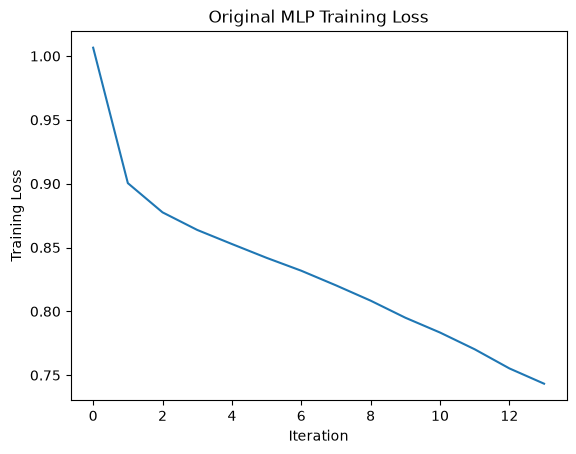

In [116]:
# Check the model's loss curve to see how its training loss changed over the 14 iterations.

plt.plot(mlp_model.loss_curve_)
plt.xlabel("Iteration")
plt.ylabel("Training Loss")
plt.title("Original MLP Training Loss")
plt.show()

- Iteration 0–1: Loss dropped sharply from about 1.0 to 0.90, meaning the model quickly improved its predictions.
- Iterations 2 onward: Loss continued to decline gradually, indicating that the model was still improving on the training data.
- Final iteration: Loss fell below 0.75, so the model continued reducing its training errors before stopping.

Overall: The curve does not show an obvious plateau in the training loss. However, because early stopping monitors the validation score, not the training loss, the model may have stopped because its validation performance stopped improving.

In [117]:
# investigating whether dimensionality reduction removed useful information for distinguishing Medium claims

# Comparing the feature shapes
print("Original training features:", X_train_combined.shape)
print("Original testing features:", X_test_combined.shape)

print("Reduced training features:", X_train_svd38.shape)
print("Reduced testing features:", X_test_svd38.shape)


Original training features: (16615, 488)
Original testing features: (5053, 488)
Reduced training features: (16615, 38)
Reduced testing features: (5053, 38)


both contain same number of claims

In [118]:
# Checking if MLP reduced stopped early
print("Iterations:", mlp_svd38.n_iter_)
print("Best validation score:", mlp_svd38.best_validation_score_)
print("Final loss:", mlp_svd38.loss_)

Iterations: 33
Best validation score: 0.5300842358604091
Final loss: 1.276828538178958


- Iterations: The reduced MLP trained for 33 iterations rather than 14, so it did not simply stop sooner.
- Validation score: The reduced MLP achieved a lower best validation score, suggesting weaker generalization during training.
- Training loss: Its higher final loss suggests it had more difficulty fitting the training data, although the loss values alone cannot establish the cause.

In [120]:
# Comparison table for original MLP and reduced MLP

models = {
    "Original MLP (488 features)": y_pred_mlp,
    "Reduced MLP (38 SVD components)": y_pred_mlp_svd38
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Low Recall": recall_score(y_test, predictions, labels=["Low"], average=None)[0],
        "Medium Recall": recall_score(y_test, predictions, labels=["Medium"], average=None)[0],
        "High Recall": recall_score(y_test, predictions, labels=["High"], average=None)[0],
        "Macro F1": f1_score(y_test, predictions, average="macro")
    })

comparison_df = pd.DataFrame(results)

metrics = ["Accuracy", "Low Recall", "Medium Recall", "High Recall", "Macro F1"]
comparison_df[metrics] = comparison_df[metrics] * 100

comparison_df.round(2)

,Model,Accuracy,Low Recall,Medium Recall,High Recall,Macro F1
0,Original MLP (488 features),57.13,31.12,36.70,84.46,50.43
1,Reduced MLP (38 SVD components),50.47,67.77,0.17,82.27,38.57


- Medium severity: The original MLP identified 36.70% of actual Medium claims, whereas the reduced MLP identified almost none.
- Low severity: The reduced MLP identified more Low claims, but this came alongside a dramatic collapse in Medium recall.
- High severity: Both models performed relatively similarly, with the original MLP doing slightly better.
- The results suggest that reducing the input from 488 features to 38 SVD components may have removed or obscured information useful for distinguishing Medium claims from Low and High claims.

Overall: The original 488-feature MLP is preferable to the 38-component MLP based on these results. It achieves better overall performance and, importantly, retains the ability to identify Medium-severity claims.

## Investigating why all models struggle in detecting low and medium claims

In [128]:
# Select numerical features from the original training data
numeric_cols = model_df.select_dtypes(include="number").columns.tolist()

# Exclude columns that should not be model inputs
numeric_cols = [
    col for col in numeric_cols
    if col not in ["Incurred", "InitialCaseEstimate"]
]

# Get training rows using your chronological split
train_data = model_df.loc[train_mask].copy()

# Compare median values across severity classes
severity_comparison = train_data.groupby("Severity")[numeric_cols].median().T

# Measure the absolute difference between Low and Medium medians
severity_comparison["Low-Medium Difference"] = (
    severity_comparison["Low"] - severity_comparison["Medium"]
).abs()

severity_comparison.sort_values(
    "Low-Medium Difference", ascending=False
).round(2)

Severity,High,Low,Medium,Low-Medium Difference
WeeklyRate,387.5,200.0,299.15,99.15
Age,36.0,28.0,31.00,3.00
ReportingDelay,22.0,24.0,23.00,1.00
AccidentHour,11.0,11.0,11.00,0.00
HoursWorkedPerWeek,38.0,38.0,38.00,0.00
DependentChildren,0.0,0.0,0.00,0.00
DependentsOther,0.0,0.0,0.00,0.00
DaysWorkedPerWeek,5.0,5.0,5.00,0.00


The numerical feature analysis compared the median values of each numerical feature across Low, Medium and High severity claims to investigate whether these features could help distinguish between the severity classes.

- **WeeklyRate:** Low claims had a median of 200.00, while Medium claims had a median of 299.15, giving an absolute difference of 99.15. This suggests that WeeklyRate may help distinguish the two classes, although the difference alone does not establish how accurately it can separate individual claims.

- **Age:** Low claims had a median age of 28 years, compared with 31 years for Medium claims, a difference of 3 years. This relatively small difference suggests that age alone may provide limited information for distinguishing these classes.

- **ReportingDelay:** The median was 24 days for Low claims and 23 days for Medium claims, a difference of only one day. This indicates that the typical reporting delay is very similar between the two classes.

- **AccidentHour and HoursWorkedPerWeek:** Both classes had identical medians of 11 hours and 38 hours per week, respectively. These identical medians indicate that the typical values of these features do not distinguish Low from Medium claims.

- **DependentChildren, DependentsOther, and DaysWorkedPerWeek:** These features also had identical medians across the classes, meaning their median values provide no clear distinction between Low and Medium claims.


**Conclusion:** The results suggest that several numerical features have similar typical values for Low and Medium claims. When features do not clearly separate these classes, models may find it difficult to learn decision boundaries that reliably distinguish them. This could partly explain why Random Forest, XGBoost and the MLP struggled to identify Low and Medium claims.

In [129]:
# Investigating claim descriptions
from sklearn.feature_extraction.text import CountVectorizer

# Use the original training claim descriptions
text_data = model_df.loc[train_mask, "ClaimDescription_Stemmed"]

# Convert descriptions into word counts
vectorizer = CountVectorizer(max_features=1000, stop_words="english")
X_words = vectorizer.fit_transform(text_data)

# Calculate average word frequency by severity class
word_df = pd.DataFrame(
    X_words.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=text_data.index
)

word_df["Severity"] = model_df.loc[train_mask, "Severity"]

word_means = word_df.groupby("Severity").mean().T

# Find words with the greatest frequency differences
word_means["High_vs_LowMedium"] = (
    word_means["High"] -
    (word_means["Low"] + word_means["Medium"]) / 2
)

word_means.sort_values(
    "High_vs_LowMedium", ascending=False
).head(15).round(4)

Severity,High,Low,Medium,High_vs_LowMedium
strain,0.7821,0.2377,0.4780,0.4242
lower,0.4531,0.0892,0.2330,0.2920
lift,0.3735,0.1465,0.2337,0.1834
shoulder,0.1863,0.0799,0.1313,0.0808
injuri,0.1578,0.0596,0.1053,0.0754
pain,0.0628,0.0094,0.0301,0.0430
fall,0.1945,0.1362,0.1757,0.0386
box,0.0809,0.0336,0.0523,0.0379
neck,0.0733,0.0240,0.0510,0.0357
ladder,0.0558,0.0278,0.0390,0.0224


The claim-description analysis compared average word frequencies in Low- and Medium-severity claims to investigate why the models struggled to distinguish between these classes.

- **Strain:** This word appeared more frequently in Medium claims (0.4780) than Low claims (0.2377). This difference may help distinguish some Medium claims from Low claims, although the word also appears in High-severity claims.

- **Lower and lift:** Both words occurred more frequently in Medium claims than Low claims. For *lower*, the average frequencies were 0.2330 for Medium and 0.0892 for Low; for *lift*, they were 0.2337 and 0.1465, respectively. These differences suggest that the words may provide some useful information, but they do not necessarily separate individual claims reliably.

- **Shoulder and injury:** These words were also more frequent in Medium claims (0.1313 and 0.1053) than Low claims (0.0799 and 0.0596). Their presence in both classes, however, limits their usefulness as standalone indicators.

- **Fall:** The average frequencies were relatively close: 0.1757 for Medium claims and 0.1362 for Low claims. This smaller difference suggests that the word may offer limited information for separating the two classes by itself.

- **Pain, box, neck, ladder, floor, fracture, soft, and tissue:** These terms generally appeared more frequently in Medium claims than Low claims, but the differences varied. Their presence in both classes means they cannot independently establish a claim's severity.

- **Knee:** This word appeared slightly more frequently in Medium claims (0.1073) than Low claims (0.0708). However, its frequency in High claims (0.1045) was also similar to Medium, so it may be less useful for distinguishing Medium claims from both other classes.


**Conclusion:** The results show that several words occur more frequently in Medium claims than Low claims, but the two classes share much of the same vocabulary. This overlap may make it difficult for models to establish reliable boundaries between them, particularly when a claim contains words associated with multiple severity categories.